<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QuMoS_ModelSecurity_Wang2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuMoS for quantum-model security: Wang et al. 2023 step by step

**Paper.** Zhepeng Wang, Jinyang Li, Zhirui Hu, Blake Gage, Elizabeth Iwasawa, Weiwen Jiang,
*QuMoS: A Framework for Preserving Security of Quantum Machine Learning Model*,
IEEE International Conference on Quantum Computing and Engineering (QCE) 2023,
DOI [10.1109/QCE57702.2023.00123](https://doi.org/10.1109/qce57702.2023.00123), arXiv [2304.11511](https://arxiv.org/abs/2304.11511).

**What this notebook does.** A well-tuned quantum neural network (QNN) is a valuable asset, and a quantum cloud provider
that runs it sees the whole circuit. QuMoS splits the QNN into several small *computing nodes* (a binary tree of 4-qubit
circuits) and sends every node to a different provider, so that one malicious provider only holds a *partial* model. A
reinforcement-learning "security engine" searches for tree layouts, node architectures and node-to-provider assignments that keep the
accuracy of the complete model high while making every partial model useless. Here we rebuild the whole pipeline on a CPU:

1. real MNIST / Fashion-MNIST images, down-sampled to 4x4 and angle-encoded on 4 qubits;
2. a batched exact simulator for the 4-qubit nodes, **asserted equal to the Qiskit circuits** (noise-free and with a gate-level depolarizing noise model built from the calibration data of the three IBM devices that the paper simulates);
3. the security-submodel finder (Algorithm 1) and the security metric `SecMec(M) = 1 - max SecAcc / Acc(M)`;
4. the LSTM controller of the security engine, random search and the "NAS on a single provider" baselines;
5. a side-by-side table with the paper's Table I and a verdict for every checkable claim.

**How to run.** Open in Google Colab (CPU runtime is enough), then *Runtime -> Run all*. `FAST_MODE = True` (default) uses a very small search budget (8 episodes per search; about 13 minutes on an idle laptop CPU, 35 minutes were measured on a heavily shared one); `FAST_MODE = False` uses the larger budgets listed in the configuration cell (24 episodes per search, 640 training images, 8 epochs; several hours on a shared CPU).

**The outputs stored in this notebook come from one `FAST_MODE = True` run.** The `FAST_MODE = False` budgets were not executed here (more than three hours on the shared machine), so every number below is a small-budget result.
No GPU, no IBM account and no token are needed (the datasets are public; an optional Hugging Face token is read only from `HF_TOKEN`).

**What you get at the end.** Our own version of Table I (accuracy, `SecMec`, `SecAcc`, number of providers and nodes for NAS-single,
random search and the QuMoS security engine on four tasks), the Pareto plot (Fig. 6), the naive-vs-QuMoS case study (Fig. 7), the
provider-count study (Fig. 8), the circuits that were actually executed, and an honest verdict for each claim.

## The paper in one page

* **Threat model (Sec. II).** A QML service hands the compiled circuit `C(theta) . D(X)` to a quantum cloud provider. A malicious
  provider can send its own data `D(Z)`, receive `C(theta) . D(Z)`, append the inverse encoder `D^-1(Z)` and recover `C(theta)`.
* **Defence (Sec. III).** Cut the model into nodes of a directed acyclic graph; each node has (i) connectivity inside a backbone graph
  (full binary tree of depth 3 = 7 nodes), (ii) a quantum architecture out of 6 options (1 *empty* + 5 circuits from Sim et al. 2019), and (iii) a quantum cloud provider (QCP) out of 3
  (simulated with the noise of `ibmq_quito`, `ibmq_belem`, `ibmq_manila`). Nodes whose input is several nodes encode each input with angle encoding and stack the encoders.
* **Security measure (Eq. 1, Algorithm 1).** Connected nodes on the same provider form a *security submodel*. `SecMec(M) = 1 - max(SecAcc) / Acc(M)`, where `SecAcc` is the best accuracy of any submodel.
* **Security engine (Sec. IV).** An LSTM controller (35 hidden units, 200 episodes, 1 sample per episode, RMSProp) samples the three properties of all nodes; each sample is trained
  (20 epochs, batch 64, Adam 5e-3, weight decay 1e-4, cosine schedule), evaluated with 8092 shots, and rewarded with `R = mean(Acc(M) - b + lambda * SecMec(M))`, `lambda in {0.1, 0.5, 1}`.
* **Data.** MNIST {0,3,6,9} and {3,6}; Fashion-MNIST {T-shirt, dress, shirt, ankle boot} and {dress, shirt}; images down-sampled to 4x4, 4 qubits, first 300 test images used for accuracy.
* **Claims (Table I, Figs. 6-8).** (i) NAS on one provider reaches 94.7-95.7 % (2 classes) and 74.7-81.7 % (4 classes); (ii) QuMoS' most accurate design is within 1.7 points of that baseline (even +0.67 on MNIST-4);
  (iii) it has much higher `SecMec` than random search (+0.12 to +0.47); (iv) the "most secure" design has `SecMec` up to 0.94 at 4-9 points of accuracy cost; (v) its Pareto front dominates random search (MNIST-4);
  (vi) a naive hand-made split is not secure; (vii) QuMoS still works with 2 or 4 providers.

### What follows the paper and what had to be chosen

The paper omits many details (exact circuits of the five architectures, input scaling, how a submodel is queried, the controller's learning-rate semantics, ...). The table lists every choice; each one is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | MNIST-2/4, Fashion-MNIST-2/4, full training sets | same four tasks; class-balanced random subsets of the real training split (`TRAIN_N`, `VAL_N` per task); test = first 300 test images of the selected classes (as in the paper) |
| Search signal | accuracy on the 300 test images | **validation split carved from the training split** (no test-set leakage); the selected designs are re-scored once on the 300 test images |
| Input | 4x4 down-sampled image, encoder of QuantumNAS (`ry, rz, rx, ry` layers) | centre-crop 24x24, 6x6 average pooling, `MinMaxScaler(0, pi)` fitted on the training split, same four-layer encoder, one pixel per qubit and layer |
| Five architectures | "5 designs from Sim et al." (not listed) | circuits 1, 2, 4, 10, 11 of Sim et al. with 2 layers on 4 qubits (wiring re-drawn from the figure; see the circuit section) |
| Node-to-node input | outputs encoded with angle encoding and stacked | Z-expectations of the child (4 values) -> `ry(pi*z)` for the first child, `rx(pi*z)` for the second child (different axes so stacked encoders do not collapse into one rotation) |
| Output / loss | log-softmax of Z-expectations (TorchQuantum) | root node: first `n_classes` Z-expectations times a fixed logit scale 3 as logits, cross-entropy |
| Training | 20 epochs, noise-aware (TorchQuantum), full data | noise-free exact simulation, budgets in the config cell (much smaller) |
| Evaluation noise | Qiskit noisy simulators `ibmq_quito/belem/manila`, 8092 shots | gate-level depolarizing channels + readout errors from the calibration of `FakeQuitoV2/FakeBelemV2/FakeManilaV2` (qiskit-ibm-runtime 0.50), exact density matrix, binomial shot noise with 8192 shots; **no transpilation/routing** |
| Partial-model query | not described | a submodel is run on its provider only; inputs that would come from a node on another provider are replaced by the 2x2 average-pooled image (angles in [0, pi]) |
| Submodel output | accuracy of the submodel | first `n_classes` Z-expectations of the submodel's tail node, argmax |
| Empty option | node and its edges removed | same; the root is never empty and nodes cut off from the root are dropped |
| "Best security" design | not defined | highest `SecMec` among sampled designs whose validation accuracy is within 10 points of the best NAS-single design |
| Controller | LSTM, RMSProp lr 0.99, PPO-style update | LSTM (35 units), RMSProp(alpha 0.9) with lr `CTRL_LR`, REINFORCE with an exponential-moving-average baseline, 1 sample per episode |
| Budgets | 200 episodes per search | `EPISODES` per search (see config) |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and Pillow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("qiskit", "qiskit_aer", "qiskit_ibm_runtime", "huggingface_hub", "pyarrow", "torch", "pylatexenc", "networkx") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub pyarrow networkx
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")

All required packages already present; skipping pip install.


In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant lives here)
SEED = 42
FAST_MODE = True               # True: tiny search budget for a class demo (a few minutes). False: the larger budgets below.
IBM_TOKEN = ""                 # optional; this notebook never needs real hardware (noise comes from the fake-backend calibration data)
DATA_DIR = "qumos_data"
N_QUBITS = 4                   # one qubit per image column, as in the paper
N_NODES = 7                    # full binary tree of depth 3 (heap numbering: node n has children 2n and 2n+1)
SHOTS = 8192                   # shots per node execution when a model is evaluated on a (simulated) provider
N_TEST = 300                   # as in the paper: first 300 test images of the selected classes
LAMBDA = 0.5                   # CHOICE: reward trade-off lambda (paper tried 0.1, 0.5, 1)
CTRL_HIDDEN = 35               # LSTM hidden units (paper)
CTRL_LR = 0.02                 # CHOICE: paper's "0.99" is not usable with a plain RMSProp step on an LSTM controller
BATCH = 32                     # CHOICE: paper 64; smaller batches give more optimiser steps from our tiny training sets
LR_NODE = 0.1                  # CHOICE: much larger than the paper's 5e-3 because we train for only ~60-160 optimiser steps
WEIGHT_DECAY = 1e-4
SECURITY_GAP = 0.10            # CHOICE: "best-security" designs must be within 10 accuracy points of the best NAS-single design

if FAST_MODE:
    TRAIN_N, VAL_N = 320, 200          # training / validation images per task (class balanced)
    EPOCHS = 6                         # paper: 20 (on the full training sets)
    EPISODES = 8                       # episodes per search (paper: 200)
    ROBUST_EPISODES = 8
else:
    TRAIN_N, VAL_N = 640, 300
    EPOCHS = 8
    EPISODES = 24
    ROBUST_EPISODES = 24

PROVIDERS = ["QCP 1 (ibmq_quito)", "QCP 2 (ibmq_belem)", "QCP 3 (ibmq_manila)", "QCP 4 (ibmq_lima)"]   # lima only for the 4-provider study
TASKS = {                      # task -> (dataset, original class labels), Sec. V-A of the paper
    "MNIST-2":        ("mnist",   [3, 6]),
    "FashionMNIST-2": ("fashion", [3, 6]),
    "MNIST-4":        ("mnist",   [0, 3, 6, 9]),
    "FashionMNIST-4": ("fashion", [0, 3, 6, 9]),
}
CLASS_NAMES = {
    "mnist":   {i: f"digit {i}" for i in range(10)},
    "fashion": {0: "T-shirt", 1: "trouser", 2: "pullover", 3: "dress", 4: "coat", 5: "sandal", 6: "shirt", 7: "sneaker", 8: "bag", 9: "ankle boot"},
}
print(f"FAST_MODE={FAST_MODE}: TRAIN_N={TRAIN_N} VAL_N={VAL_N} EPOCHS={EPOCHS} EPISODES={EPISODES} ROBUST_EPISODES={ROBUST_EPISODES}")

FAST_MODE=True: TRAIN_N=320 VAL_N=200 EPOCHS=6 EPISODES=8 ROBUST_EPISODES=8


In [3]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"): os.environ.setdefault(_v, "1")
import io, gzip, time, struct, shutil, warnings, itertools, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(1)            # many tiny tensor operations: extra threads only add contention
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit_ibm_runtime.fake_provider import FakeQuitoV2, FakeBelemV2, FakeManilaV2, FakeLimaV2

HF_TOKEN = os.environ.get("HF_TOKEN")              # the four datasets are public; a token is only used if present
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
CDT, RDT = torch.complex128, torch.float64          # exact double precision: the simulator is asserted equal to Qiskit below
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)
T_NOTEBOOK_START = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu
qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0


## 1. Data: real MNIST and Fashion-MNIST images

The paper evaluates on MNIST and Fashion-MNIST sub-problems. Both datasets are public; we read the parquet files of the Hugging Face mirrors
(`ylecun/mnist`, `zalando-datasets/fashion_mnist`) and fall back to the original IDX files. For every task we keep only its classes and draw
three **disjoint** parts: a class-balanced random *training* subset and a *validation* subset from the dataset's training split (the validation images drive the architecture search),
and the *first `N_TEST` test images* of the selected classes (as in the paper) for the final numbers. The raw download is deleted afterwards if it is large.

In [4]:
HF_PARQUET = {"mnist":   ("ylecun/mnist", "mnist/{split}-00000-of-00001.parquet"),
              "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist/{split}-00000-of-00001.parquet")}
IDX_FALLBACK = {   # direct mirrors (gz IDX files) in case the Hugging Face download fails
    "mnist": ["https://ossci-datasets.s3.amazonaws.com/mnist/{f}", "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"],
    "fashion": ["http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/{f}", "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/{f}"]}
IDX_FILES = {"train": ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"), "test": ("t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz")}

def _read_idx(raw):
    magic, = struct.unpack(">I", raw[:4]); nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, raw[4:4 + 4 * nd])
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def _http_get(urls, path):
    import requests
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=(10, 120)); r.raise_for_status(); open(path, "wb").write(r.content); return path
        except Exception as e:
            last = e; print("  download failed:", u, type(e).__name__)
    raise RuntimeError(f"all mirrors failed: {last}")

def load_split(name, split):
    """All images (uint8, 28x28) and labels of one split of `name`; the raw parquet is read from the HF cache and the result is cached as .npz in DATA_DIR."""
    cache = os.path.join(DATA_DIR, f"{name}_{split}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["x"], z["y"]
    try:
        from huggingface_hub import hf_hub_download
        from PIL import Image
        repo, fn = HF_PARQUET[name]
        path = hf_hub_download(repo, fn.format(split=split), repo_type="dataset", token=HF_TOKEN, cache_dir=os.path.join(DATA_DIR, "hf_cache"))
        df = pd.read_parquet(path)
        x = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8); y = df["label"].to_numpy().astype(int)
    except Exception as e:
        print(f"  Hugging Face download failed ({type(e).__name__}); using the IDX mirrors")
        fi, fl = IDX_FILES[split]
        urls = IDX_FALLBACK[name]
        pi = _http_get([u.format(f=fi) for u in urls], os.path.join(DATA_DIR, fi)); pl = _http_get([u.format(f=fl) for u in urls], os.path.join(DATA_DIR, fl))
        x = _read_idx(gzip.open(pi).read()); y = _read_idx(gzip.open(pl).read()).astype(int)
    np.savez_compressed(cache, x=x, y=y)
    return x, y

def get_task_data(task):
    """Disjoint train / validation / test subsets (28x28 uint8 images + ORIGINAL labels) of one task."""
    ds, classes = TASKS[task]
    xtr, ytr = load_split(ds, "train"); xte, yte = load_split(ds, "test")
    rng_t = np.random.default_rng(SEED + 17 * len(classes) + (1 if ds == "fashion" else 0))
    pool = {c: rng_t.permutation(np.where(ytr == c)[0]) for c in classes}
    n_tr, n_va = TRAIN_N // len(classes), VAL_N // len(classes)
    i_tr = np.concatenate([pool[c][:n_tr] for c in classes]); i_va = np.concatenate([pool[c][n_tr:n_tr + n_va] for c in classes])
    i_tr, i_va = rng_t.permutation(i_tr), rng_t.permutation(i_va)
    i_te = np.where(np.isin(yte, classes))[0][:N_TEST]                                       # first N_TEST images of the selected classes, file order (paper)
    return {"classes": classes, "train": (xtr[i_tr], ytr[i_tr]), "val": (xtr[i_va], ytr[i_va]), "test": (xte[i_te], yte[i_te])}

RAW = {t: get_task_data(t) for t in TASKS}
for t, d in RAW.items():
    print(f"{t:15s} classes={d['classes']}  train={d['train'][0].shape}  val={d['val'][0].shape}  test={d['test'][0].shape}")
for f in [os.path.join(dp, fn) for dp, _, fns in os.walk(DATA_DIR) for fn in fns]:
    if os.path.getsize(f) > 50e6: os.remove(f); print("deleted large raw file", f)

MNIST-2         classes=[3, 6]  train=(320, 28, 28)  val=(200, 28, 28)  test=(300, 28, 28)
FashionMNIST-2  classes=[3, 6]  train=(320, 28, 28)  val=(200, 28, 28)  test=(300, 28, 28)
MNIST-4         classes=[0, 3, 6, 9]  train=(320, 28, 28)  val=(200, 28, 28)  test=(300, 28, 28)
FashionMNIST-4  classes=[0, 3, 6, 9]  train=(320, 28, 28)  val=(200, 28, 28)  test=(300, 28, 28)


## 2. Pre-processing (fitted on the training split only)

As in QuantumNAS (the encoder the paper uses): centre-crop the 28x28 image to 24x24, average-pool with a 6x6 window to get a **4x4 image**, flatten to 16 numbers, and scale them to the angle range
`[0, pi]` with a `MinMaxScaler` that is **fitted on the training split only** (validation and test angles are clipped to `[0, pi]`). The 16 numbers are loaded onto the 4 qubits by four rotation layers
(`ry` with pixels 0-3, `rz` with 4-7, `rx` with 8-11, `ry` with 12-15), i.e. one pixel per qubit and layer. A node that is *not* fed by other nodes (a "head" node) receives this image encoder;
a node fed by other nodes receives the outputs of those nodes instead (Sec. III-B.2).

In [5]:
def to_4x4(x28):
    """(N,28,28) uint8 -> (N,16) float in [0,1]: centre crop 24x24 then 6x6 average pooling."""
    x = x28[:, 2:26, 2:26].astype(np.float64) / 255.0
    return x.reshape(-1, 4, 6, 4, 6).mean(axis=(2, 4)).reshape(-1, 16)

DATA = {}
for t, d in RAW.items():
    classes = d["classes"]; cmap = {c: i for i, c in enumerate(classes)}
    f_tr, f_va, f_te = (to_4x4(d[s][0]) for s in ("train", "val", "test"))
    sc = MinMaxScaler((0, np.pi)).fit(f_tr)                                              # train-only fit
    ang = {s: np.clip(sc.transform(f), 0, np.pi) for s, f in zip(("train", "val", "test"), (f_tr, f_va, f_te))}
    DATA[t] = {"classes": classes, "n_cls": len(classes), "scaler": sc,
               **{s: {"ang": torch.tensor(ang[s], dtype=RDT), "y": torch.tensor([cmap[v] for v in d[s][1]]), "y_orig": d[s][1], "img": d[s][0]} for s in ("train", "val", "test")}}
    print(f"{t:15s} angles train {ang['train'].shape} range [{ang['train'].min():.2f},{ang['train'].max():.2f}] | test clipped to [{ang['test'].min():.2f},{ang['test'].max():.2f}]")

MNIST-2         angles train (320, 16) range [0.00,3.14] | test clipped to [0.00,3.14]
FashionMNIST-2  angles train (320, 16) range [0.00,3.14] | test clipped to [0.00,3.14]
MNIST-4         angles train (320, 16) range [0.00,3.14] | test clipped to [0.00,3.14]
FashionMNIST-4  angles train (320, 16) range [0.00,3.14] | test clipped to [0.00,3.14]


## Dataset Exploration and Visualisation

Everything below shows the **real** images and their **ground-truth** labels (no synthetic data). For each of the four tasks we print the shapes, the feature names (the 16 pixels of the 4x4 image that become rotation angles) and the original class labels with their counts in the train/validation/test parts,
draw example images, the class distribution, and a 2-D scatter of the real samples coloured by their true class: first the raw PCA coordinates (PCA fitted on the training split), then the same coordinates scaled to `[0, pi]` (the range of the rotation angles) and, because the model is fed with the angles directly, the first two input angles.

In [6]:
FEATURE_NAMES = [f"px(r{r},c{c})" for r in range(4) for c in range(4)]
rows = []
for t, D in DATA.items():
    ds, classes = TASKS[t]
    print(f"== {t}: dataset={ds}, shape train/val/test = {tuple(D['train']['ang'].shape)}/{tuple(D['val']['ang'].shape)}/{tuple(D['test']['ang'].shape)}, raw image {D['train']['img'].shape[1:]} uint8")
    print("   features:", FEATURE_NAMES[:4], "...", FEATURE_NAMES[-2:], "(16 angles = 4 rotation layers x 4 qubits)")
    for s in ("train", "val", "test"):
        u, c = np.unique(D[s]["y_orig"], return_counts=True)
        print(f"   {s:5s} original labels -> counts:", {f'{int(a)} ({CLASS_NAMES[ds][int(a)]})': int(b) for a, b in zip(u, c)})
        for a, b in zip(u, c): rows.append({"task": t, "split": s, "label": int(a), "class": CLASS_NAMES[ds][int(a)], "count": int(b)})
CLASS_TABLE = pd.DataFrame(rows)

== MNIST-2: dataset=mnist, shape train/val/test = (320, 16)/(200, 16)/(300, 16), raw image (28, 28) uint8
   features: ['px(r0,c0)', 'px(r0,c1)', 'px(r0,c2)', 'px(r0,c3)'] ... ['px(r3,c2)', 'px(r3,c3)'] (16 angles = 4 rotation layers x 4 qubits)
   train original labels -> counts: {'3 (digit 3)': 160, '6 (digit 6)': 160}
   val   original labels -> counts: {'3 (digit 3)': 100, '6 (digit 6)': 100}
   test  original labels -> counts: {'3 (digit 3)': 162, '6 (digit 6)': 138}
== FashionMNIST-2: dataset=fashion, shape train/val/test = (320, 16)/(200, 16)/(300, 16), raw image (28, 28) uint8
   features: ['px(r0,c0)', 'px(r0,c1)', 'px(r0,c2)', 'px(r0,c3)'] ... ['px(r3,c2)', 'px(r3,c3)'] (16 angles = 4 rotation layers x 4 qubits)
   train original labels -> counts: {'3 (dress)': 160, '6 (shirt)': 160}
   val   original labels -> counts: {'3 (dress)': 100, '6 (shirt)': 100}
   test  original labels -> counts: {'3 (dress)': 144, '6 (shirt)': 156}
== MNIST-4: dataset=mnist, shape train/val/test =

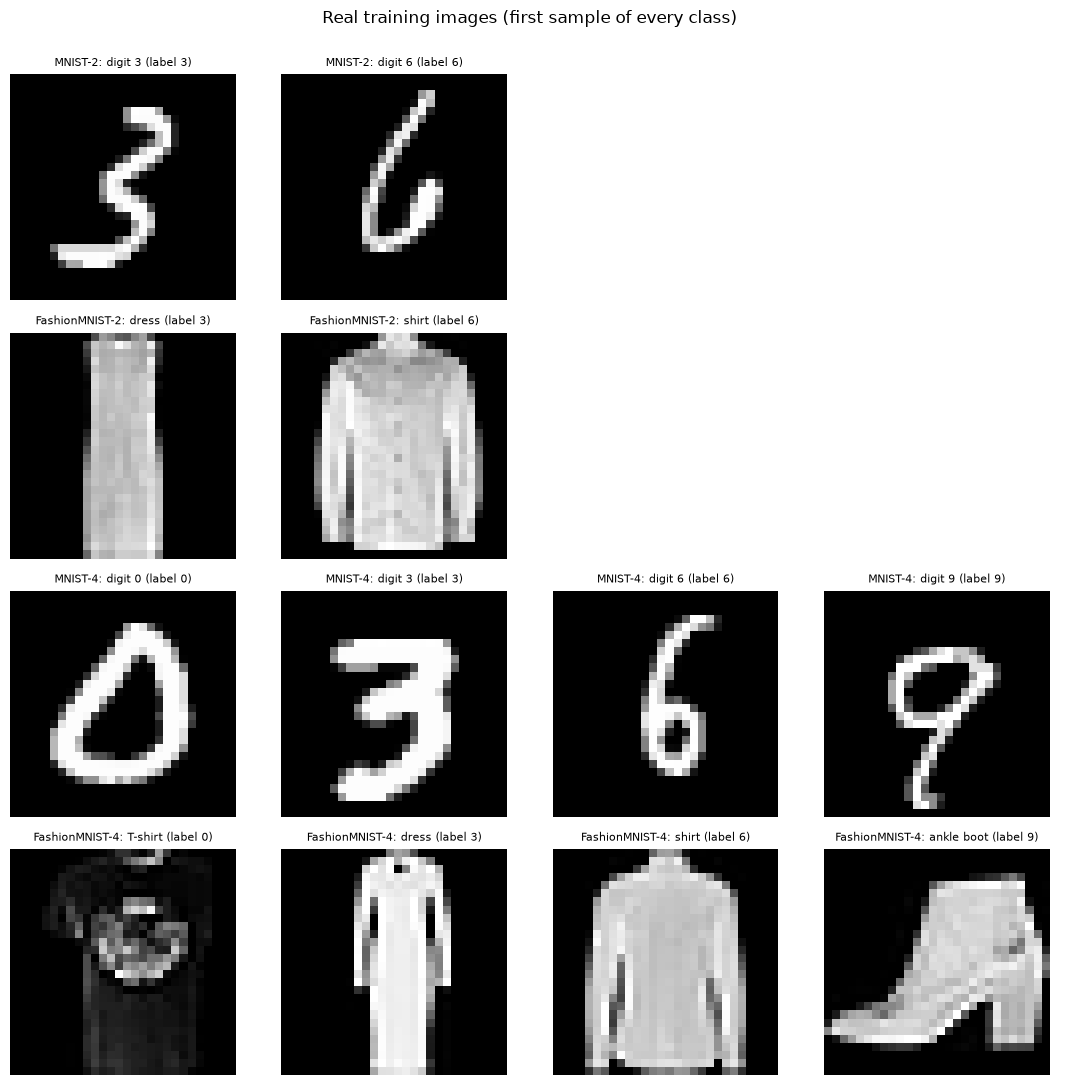

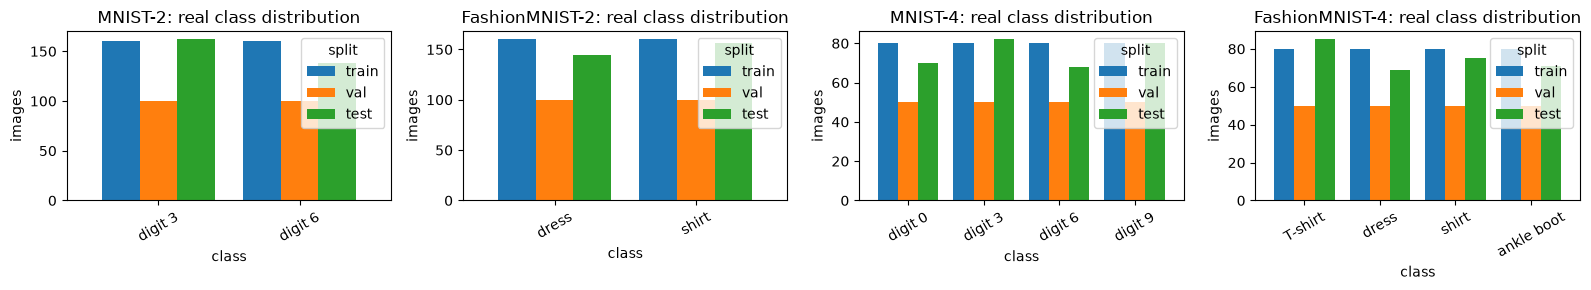

In [7]:
fig, axes = plt.subplots(len(TASKS), 4, figsize=(11, 2.7 * len(TASKS)))
for r, (t, D) in enumerate(DATA.items()):
    ds, classes = TASKS[t]
    for k in range(4):
        ax = axes[r, k]; ax.axis("off")
        if k < len(classes):
            c = classes[k]; idx = np.where(D["train"]["y_orig"] == c)[0][0]
            ax.imshow(D["train"]["img"][idx], cmap="gray"); ax.set_title(f"{t}: {CLASS_NAMES[ds][c]} (label {c})", fontsize=8)
plt.suptitle("Real training images (first sample of every class)", y=1.0); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(TASKS), figsize=(4 * len(TASKS), 3))
for ax, t in zip(axes, TASKS):
    ds, classes = TASKS[t]; sub = CLASS_TABLE[CLASS_TABLE.task == t].pivot(index="class", columns="split", values="count")[["train", "val", "test"]]
    sub = sub.loc[[CLASS_NAMES[ds][c] for c in classes]]; sub.plot.bar(ax=ax, rot=30, width=0.8); ax.set_title(f"{t}: real class distribution"); ax.set_ylabel("images")
plt.tight_layout(); plt.show()

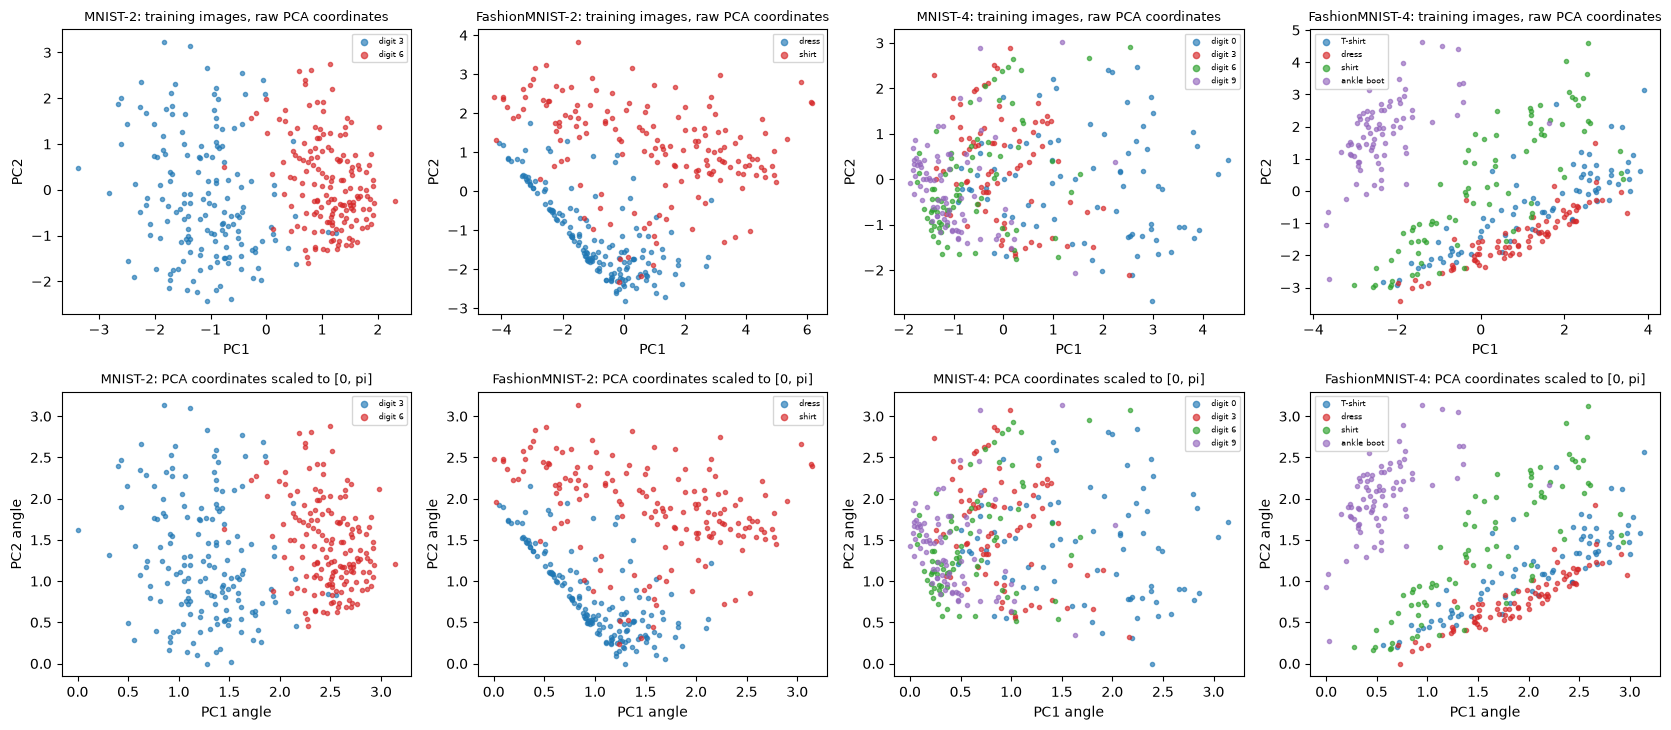

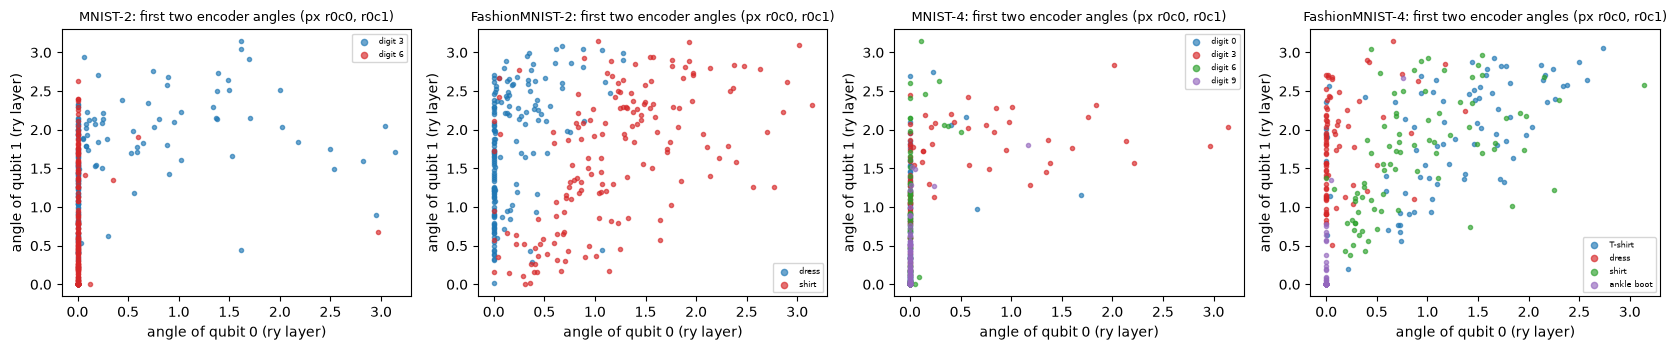

In [8]:
PALETTE = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]
def scatter_by_class(ax, xy, y_orig, ds, title):
    for i, c in enumerate(sorted(np.unique(y_orig))):
        m = y_orig == c; ax.scatter(xy[m, 0], xy[m, 1], s=9, alpha=0.65, color=PALETTE[i], label=CLASS_NAMES[ds][int(c)])
    ax.set_title(title, fontsize=9); ax.legend(fontsize=6, markerscale=1.5)

PCA_XY = {}
fig, axes = plt.subplots(2, len(TASKS), figsize=(4.2 * len(TASKS), 7.4))
for k, (t, D) in enumerate(DATA.items()):
    ds, _ = TASKS[t]
    pca = PCA(n_components=2, random_state=SEED).fit(D["train"]["ang"].numpy())                 # fitted on the training split
    xy = pca.transform(D["train"]["ang"].numpy()); sc2 = MinMaxScaler((0, np.pi)).fit(xy)
    PCA_XY[t] = (xy, sc2.transform(xy))
    scatter_by_class(axes[0, k], xy, D["train"]["y_orig"], ds, f"{t}: training images, raw PCA coordinates")
    scatter_by_class(axes[1, k], PCA_XY[t][1], D["train"]["y_orig"], ds, f"{t}: PCA coordinates scaled to [0, pi]")
    axes[1, k].set_xlabel("PC1 angle"); axes[0, k].set_xlabel("PC1"); axes[0, k].set_ylabel("PC2"); axes[1, k].set_ylabel("PC2 angle")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(TASKS), figsize=(4.2 * len(TASKS), 3.6))
for ax, (t, D) in zip(axes, DATA.items()):
    scatter_by_class(ax, D["train"]["ang"].numpy()[:, :2], D["train"]["y_orig"], TASKS[t][0], f"{t}: first two encoder angles (px r0c0, r0c1)")
    ax.set_xlabel("angle of qubit 0 (ry layer)"); ax.set_ylabel("angle of qubit 1 (ry layer)")
plt.tight_layout(); plt.show()

### Classical baseline on the identical inputs

Before any quantum model: the same 16 angles (training split) are given to classical classifiers and scored on the same 300 test images. These numbers say how much of the task is solvable from a 4x4 image at all.

In [9]:
def classical_baselines(t):
    D = DATA[t]; Xtr, ytr = D["train"]["ang"].numpy(), D["train"]["y"].numpy(); Xte, yte = D["test"]["ang"].numpy(), D["test"]["y"].numpy()
    models = {"SVC (rbf, C=1)": SVC(C=1.0, kernel="rbf", random_state=SEED), "RandomForest (200)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
              "MLP (32,16)": MLPClassifier((32, 16), max_iter=600, random_state=SEED), "Logistic regression": LogisticRegression(max_iter=2000)}
    out = {}
    for name, m in models.items():
        t0 = time.time(); m.fit(Xtr, ytr); out[name] = (100 * (m.predict(Xte) == yte).mean(), time.time() - t0)
    return out
BASE = {t: classical_baselines(t) for t in TASKS}
CLASSICAL_TABLE = pd.DataFrame({t: {k: round(v[0], 2) for k, v in b.items()} for t, b in BASE.items()}).T
print("Test accuracy (%) of classical models on the identical 4x4 angle inputs (300 test images):"); display(CLASSICAL_TABLE)

Test accuracy (%) of classical models on the identical 4x4 angle inputs (300 test images):


,"SVC (rbf, C=1)",RandomForest (200),"MLP (32,16)",Logistic regression
MNIST-2,97.33,95.33,97.67,97.00
FashionMNIST-2,91.00,92.67,92.33,90.00
MNIST-4,91.00,89.33,91.67,87.67
FashionMNIST-4,83.67,83.67,83.67,82.67


## 3. The computing node: a 4-qubit circuit

Every node of QuMoS is a small quantum neural network on 4 qubits:

`|0000>  ->  input encoder (angle encoding)  ->  trainable block (one of 5 architectures)  ->  measure <Z> on every qubit`.

* **Input encoder.** A head node receives the image through the four-layer encoder (`ry, rz, rx, ry`). A node fed by one or two other nodes encodes each child's four Z-expectations `z` as `ry(pi*z)` (first child) and `rx(pi*z)` (second child) and stacks them, as described in Sec. III-B.2.
* **Five trainable architectures** (Sim, Johnson, Aspuru-Guzik 2019, circuits 1, 2, 4, 10, 11 with two layers): `A1` = `rx, rz` layers; `A2` = `A1` + a CNOT ladder; `A3` = `A1` + a controlled-`rx` ladder; `A4` = `ry` layers + CZ ring; `A5` = `ry, rz` layers + CNOT pairs and a middle block. Architecture `0` is the *empty* option (the node is removed).
* **Output.** The four Z-expectations in `[-1, 1]` (they are what travels to the next node, or, at the root, become the class scores).

We describe each architecture **once** as a list of layers. From that list we derive (a) a fast fused unitary for training (all nodes of a model are built in one batched operation), (b) a gate-by-gate density-matrix simulator with noise for evaluation (and a faster, mathematically identical form of it that pre-computes the noisy channel of a trained block), and (c) the Qiskit circuit that is drawn and used as the reference. The next subsection asserts that they all agree.

In [10]:
ALL_Q = (0, 1, 2, 3)
ARCH_NAMES = {0: "empty", 1: "A1 (Sim c.1)", 2: "A2 (Sim c.2)", 3: "A3 (Sim c.4)", 4: "A4 (Sim c.10)", 5: "A5 (Sim c.11)"}
# CHOICE: wiring of the five Sim et al. circuits is re-drawn from the figure of Sim et al. (2019); two repetitions of each layer block.
LAYERS = {
    1: [("rot", "rx", ALL_Q), ("rot", "rz", ALL_Q)] * 2,
    2: [("rot", "rx", ALL_Q), ("rot", "rz", ALL_Q), ("cx", ((3, 2), (2, 1), (1, 0)))] * 2,
    3: [("rot", "rx", ALL_Q), ("rot", "rz", ALL_Q), ("crx", ((3, 2), (2, 1), (1, 0)))] * 2,
    4: [("rot", "ry", ALL_Q), ("cz", ((0, 1), (1, 2), (2, 3), (3, 0)))] * 2 + [("rot", "ry", ALL_Q)],
    5: [("rot", "ry", ALL_Q), ("rot", "rz", ALL_Q), ("cx", ((0, 1), (2, 3))), ("rot", "ry", (1, 2)), ("rot", "rz", (1, 2)), ("cx", ((1, 2),))] * 2,
}
def n_params(a):
    return sum(len(l[2]) if l[0] == "rot" else (len(l[1]) if l[0] == "crx" else 0) for l in LAYERS[a])
def block_gates(a):
    """The architecture as a gate list [(name, qubits, parameter index or None)] - the single source for the DM simulator and the Qiskit circuit."""
    gates, p = [], 0
    for l in LAYERS[a]:
        if l[0] == "rot":
            for q in l[2]: gates.append((l[1], (q,), p)); p += 1
        elif l[0] == "crx":
            for (c, t) in l[1]: gates.append(("crx", (c, t), p)); p += 1
        else:
            for (c, t) in l[1]: gates.append((l[0], (c, t), None))
    return gates
NP = {a: n_params(a) for a in LAYERS}
print({ARCH_NAMES[a]: f"{NP[a]} trainable parameters, {len(block_gates(a))} gates" for a in LAYERS})

{'A1 (Sim c.1)': '16 trainable parameters, 16 gates', 'A2 (Sim c.2)': '16 trainable parameters, 22 gates', 'A3 (Sim c.4)': '22 trainable parameters, 22 gates', 'A4 (Sim c.10)': '12 trainable parameters, 20 gates', 'A5 (Sim c.11)': '24 trainable parameters, 30 gates'}


In [11]:
# ---------- (a) fast fused simulator used for training (exact, noise free, differentiable) ----------
I2 = torch.eye(2, dtype=CDT)
P0 = torch.tensor([[1, 0], [0, 0]], dtype=CDT); P1 = torch.tensor([[0, 0], [0, 1]], dtype=CDT)
BITS = torch.tensor([[(i >> (3 - q)) & 1 for q in range(4)] for i in range(16)])        # qubit 0 = most significant bit (tensor axis 0)
ZSIGN = (1.0 - 2.0 * BITS).to(RDT)                                                      # (16,4): eigenvalue of Z_q on basis state i

def rot(axis, theta):
    """Single-qubit rotation matrices, shape (..., 2, 2), for angles theta (...)."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2); z = torch.zeros_like(c)
    if axis == "ry": re, im = [c, -s, s, c], [z, z, z, z]
    elif axis == "rx": re, im = [c, z, z, c], [z, -s, -s, z]
    elif axis == "rz": re, im = [c, z, z, c], [-s, z, z, s]
    return torch.complex(torch.stack(re, -1), torch.stack(im, -1)).reshape(*theta.shape, 2, 2)

def kron4(m0, m1, m2, m3):
    """Tensor product of four 2x2 matrices (leading batch dimensions broadcast) -> (...,16,16)."""
    out = torch.einsum("...ab,...cd,...ef,...gh->...acegbdfh", m0, m1, m2, m3)
    return out.reshape(*out.shape[:-8], 16, 16)

def embed(mats):
    """16x16 operator that applies the 2x2 matrices {qubit: matrix} and the identity elsewhere."""
    return kron4(*[mats.get(q, I2) for q in range(4)])

def gate_matrix(name, qubits, theta=None):
    """Full 16x16 matrix of one gate of the gate list (theta broadcastable for rotations)."""
    if name in ("rx", "ry", "rz"): return embed({qubits[0]: rot(name, theta)})
    if name == "h": return embed({qubits[0]: torch.tensor([[1, 1], [1, -1]], dtype=CDT) / math.sqrt(2)})
    c, t = qubits
    if name == "cx": return embed({c: P0}) + embed({c: P1, t: torch.tensor([[0, 1], [1, 0]], dtype=CDT)})
    if name == "cz": return embed({c: P0}) + embed({c: P1, t: torch.diag(torch.tensor([1, -1], dtype=CDT))})
    if name == "crx": return embed({c: P0}) + embed({c: P1, t: rot("rx", theta)})
    raise ValueError(name)

# Batched unitary builder. Every architecture is turned into NI "items" (a layer of single-qubit rotations, one controlled-rx, or a constant CX/CZ layer); item k is
#   K_k = kron(slot matrices) @ C_k + A_k
# with slot 0 = identity, slot 1 = |1><1|, slot 2+p = rotation number p. The unitary is the ordered product of the items, evaluated as a binary tree of batched matmuls.
NI, NPMAX, AXES3 = 16, 24, ["rx", "ry", "rz"]
def _build_tables():
    SLOT = torch.zeros(6, NI, 4, dtype=torch.long); CM = torch.eye(16, dtype=CDT).repeat(6, NI, 1, 1); CA = torch.zeros(6, NI, 16, 16, dtype=CDT); AXM = torch.zeros(6, NPMAX, 3, dtype=CDT)
    for a in LAYERS:
        it, p = 0, 0
        for l in LAYERS[a]:
            if l[0] == "rot":
                for q in l[2]: SLOT[a, it, q] = 2 + p; AXM[a, p, AXES3.index(l[1])] = 1; p += 1
                it += 1
            elif l[0] == "crx":
                for (c, t) in l[1]:
                    SLOT[a, it, c] = 1; SLOT[a, it, t] = 2 + p; AXM[a, p, 0] = 1; CA[a, it] = embed({c: P0}); p += 1; it += 1
            else:
                U = torch.eye(16, dtype=CDT)
                for (c, t) in l[1]: U = gate_matrix(l[0], (c, t)) @ U
                CM[a, it] = U; it += 1
        assert it <= NI and p == NP[a]
    return SLOT, CM, CA, AXM
SLOT_T, CM_T, CA_T, AXM_T = _build_tables()

def build_unitaries(ids, theta):
    """ids: architecture id per node (list), theta: (n_nodes, NPMAX) parameters (only the first NP[a] entries of a row are used). Returns (n_nodes,16,16) unitaries."""
    ids = torch.as_tensor(ids); Nn = len(ids)
    c, s = torch.cos(theta / 2), torch.sin(theta / 2); z = torch.zeros_like(c)
    re = torch.stack([torch.stack([c, z, z, c], -1), torch.stack([c, -s, s, c], -1), torch.stack([c, z, z, c], -1)], -2)          # rx, ry, rz real parts
    im = torch.stack([torch.stack([z, -s, -s, z], -1), torch.stack([z, z, z, z], -1), torch.stack([-s, z, z, s], -1)], -2)         # imaginary parts
    R = torch.einsum("npx,npxk->npk", AXM_T[ids], torch.complex(re, im)).reshape(Nn, NPMAX, 2, 2)
    M = torch.cat([I2.expand(Nn, 1, 2, 2), P1.expand(Nn, 1, 2, 2), R], 1)
    G = M[torch.arange(Nn)[:, None, None], SLOT_T[ids]]                                                                           # (Nn, NI, 4, 2, 2)
    X = kron4(G[:, :, 0], G[:, :, 1], G[:, :, 2], G[:, :, 3]) @ CM_T[ids] + CA_T[ids]
    while X.shape[1] > 1: X = X[:, 1::2] @ X[:, 0::2]                                                                               # later items multiply from the left
    return X[:, 0]

def block_unitary(a, theta):
    """Unitary of one architecture with trainable parameters theta (NP[a],)."""
    return build_unitaries([a], F.pad(theta, (0, NPMAX - len(theta)))[None])[0]

AXIS_ONEHOT = {ax: torch.tensor([float(ax == a2) for a2 in AXES3], dtype=CDT) for ax in AXES3}
def encode_state(slots):
    """Input encoder as a product state. slots = [(axis, angles (B,4)), ...] applied in order -> state vector (B,16).
    All rotations of one qubit are multiplied into a single 2x2 matrix (binary tree of batched matmuls) and applied to |0>."""
    B = slots[0][1].shape[0]
    ang = torch.stack([a for _, a in slots])                                              # (S, B, 4)
    mask = torch.stack([AXIS_ONEHOT[ax] for ax, _ in slots])                              # (S, 3)
    c, s = torch.cos(ang / 2), torch.sin(ang / 2); z = torch.zeros_like(c)
    re = torch.stack([torch.stack([c, z, z, c], -1), torch.stack([c, -s, s, c], -1), torch.stack([c, z, z, c], -1)], -2)           # rx, ry, rz
    im = torch.stack([torch.stack([z, -s, -s, z], -1), torch.stack([z, z, z, z], -1), torch.stack([-s, z, z, s], -1)], -2)
    R = torch.einsum("sx,sbqxk->sbqk", mask, torch.complex(re, im)).reshape(len(slots), B, 4, 2, 2)
    while R.shape[0] > 1:                                                                  # product R_S ... R_2 R_1
        if R.shape[0] % 2: R = torch.cat([R, torch.eye(2, dtype=CDT).expand(1, B, 4, 2, 2)])
        R = R[1::2] @ R[0::2]
    v = R[0][..., 0]                                                                       # first column = state after the rotations acting on |0>
    return torch.einsum("bi,bj,bk,bl->bijkl", v[:, 0], v[:, 1], v[:, 2], v[:, 3]).reshape(B, 16)

IMG_AXES = ["ry", "rz", "rx", "ry"]
def img_slots(ang):  return [(ax, ang[:, 4 * j:4 * j + 4]) for j, ax in enumerate(IMG_AXES)]
def child_slots(vals_list): return [(ax, v) for ax, v in zip(("ry", "rx"), vals_list)]

def node_free(a, theta, slots):
    """Noise-free node: returns the four Z-expectations (B,4)."""
    psi = encode_state(slots) @ block_unitary(a, theta).T
    return (psi.real ** 2 + psi.imag ** 2) @ ZSIGN

In [12]:
# ---------- (b) gate-by-gate density-matrix simulator with depolarizing noise and readout errors ----------
def dep_channel(rho, qubits, lam):
    """Depolarizing channel rho -> (1-lam) rho + lam * Tr_q(rho) (x) I/2^k on the given qubits (Qiskit's depolarizing_error(lam, k))."""
    if lam == 0.0: return rho
    k = len(qubits); B = rho.shape[0]; t = rho.reshape(B, *([2] * 8))
    ket = [1 + q for q in qubits]; bra = [5 + q for q in qubits]
    rest = [ax for ax in range(1, 9) if ax not in ket + bra]
    perm = [0] + rest + ket + bra
    tp = t.permute(perm); shp = tp.shape; d = 2 ** k
    m = tp.reshape(B, -1, d, d)                                       # (B, rest, d, d)
    tr = torch.diagonal(m, dim1=-2, dim2=-1).sum(-1)                  # partial trace over the selected qubits
    new = (1 - lam) * m + (lam / d) * tr[..., None, None] * torch.eye(d, dtype=rho.dtype)
    inv = np.argsort(perm)
    return new.reshape(shp).permute(*[int(i) for i in inv]).reshape(B, 16, 16)

def apply_gate(rho, U):
    return U @ rho @ U.conj().transpose(-1, -2)

def expand_gate(name, qubits, theta):
    """Native-gate expansion used on a provider: a controlled-rx is not a native gate, so it runs as rz(pi/2) ry(theta/2) cx ry(-theta/2) cx rz(-pi/2) on the target
    (exact identity, checked below); every other gate is native. Returns [(name, qubits, angle)] in time order."""
    if name != "crx": return [(name, qubits, theta)]
    c, t = qubits; half = torch.as_tensor(theta) / 2
    return [("rz", (t,), torch.tensor(math.pi / 2, dtype=RDT)), ("ry", (t,), half), ("cx", (c, t), None), ("ry", (t,), -half), ("cx", (c, t), None), ("rz", (t,), torch.tensor(-math.pi / 2, dtype=RDT))]

def node_density(a, theta, slots, noise=None):
    """Reference: gate-by-gate simulation of a node. noise = dict gate-name -> depolarizing parameter (None = ideal). Returns (rho, ideal-readout Z-expectations (B,4))."""
    B = slots[0][1].shape[0]
    rho = torch.zeros(B, 16, 16, dtype=CDT); rho[:, 0, 0] = 1
    lam = (lambda g: 0.0) if noise is None else (lambda g: noise[g])
    for axis, ang in slots:                                                    # encoder gates, one per qubit
        for q in range(4):
            rho = dep_channel(apply_gate(rho, embed({q: rot(axis, ang[:, q])})), (q,), lam(axis))
    for (name, qs, p) in block_gates(a):                                       # trainable block, gate by gate (crx expanded into native gates)
        for (n2, q2, th2) in expand_gate(name, qs, None if p is None else theta[p]):
            rho = dep_channel(apply_gate(rho, gate_matrix(n2, q2, th2)), q2, lam(n2))
    probs = torch.diagonal(rho, dim1=-2, dim2=-1).real
    return rho, probs @ ZSIGN

# Fast but identical form for evaluation: (i) the noisy encoder of every qubit is a single-qubit mixed state (depolarizing noise only shrinks the Bloch vector), (ii) after training,
# the noisy trainable block is a fixed linear map on density matrices (a 256x256 "superoperator"), obtained once by pushing the 256 matrix units through the noisy gate sequence.
def node_superop(a, theta, noise):
    rho = torch.eye(256, dtype=CDT).reshape(256, 16, 16)
    for (name, qs, p) in block_gates(a):
        for (n2, q2, th2) in expand_gate(name, qs, None if p is None else theta[p]):
            rho = dep_channel(apply_gate(rho, gate_matrix(n2, q2, th2)), q2, noise[n2])
    return rho.reshape(256, 256)

def noisy_encoder(slots, noise):
    B = slots[0][1].shape[0]; rq = torch.zeros(B, 4, 2, 2, dtype=CDT); rq[..., 0, 0] = 1
    for axis, ang in slots:
        R = rot(axis, ang); rq = R @ rq @ R.conj().transpose(-1, -2)
        rq = (1 - noise[axis]) * rq + (noise[axis] / 2) * I2                  # trace is 1, so Tr(rho) I/2 = I/2
    return torch.einsum("bpq,brs,btu,bvw->bprtvqsuw", rq[:, 0], rq[:, 1], rq[:, 2], rq[:, 3]).reshape(B, 16, 16)

def node_noisy(S, slots, noise):
    """Ideal-readout Z-expectations of a node after the noisy encoder and the (pre-computed) noisy block."""
    rho = noisy_encoder(slots, noise); B = rho.shape[0]
    out = (rho.reshape(B, 256) @ S).reshape(B, 16, 16)
    return torch.diagonal(out, dim1=-2, dim2=-1).real @ ZSIGN

# ---- noise parameters of the three simulated providers, derived from the fake-backend calibration data ----
def provider_noise(backend):
    """Depolarizing parameters per gate type and per-qubit readout map z' = A z + B from a fake IBM backend (qiskit-ibm-runtime)."""
    tg, pr = backend.target, backend.properties()
    e_sx = float(np.mean([tg["sx"][(q,)].error for q in range(backend.num_qubits)]))
    e_cx = float(np.mean([v.error for v in tg["cx"].values()]))
    lam1, lam2 = 2 * e_sx, (4.0 / 3.0) * e_cx          # average gate infidelity e -> depolarizing parameter lambda = e d/(d-1)
    # CHOICE: rx, ry cost two sx pulses, h one sx, rz is virtual (free); cx and cz cost one cx; crx runs as 2 ry + 2 cx (expand_gate). Routing/SWAPs on the device coupling map are NOT modelled.
    noise = {"rx": 1 - (1 - lam1) ** 2, "ry": 1 - (1 - lam1) ** 2, "rz": 0.0, "h": lam1, "cx": lam2, "cz": lam2}
    p10 = np.array([pr.qubit_property(q)["prob_meas1_prep0"][0] for q in range(4)])      # P(read 1 | prepared 0), physical qubits 0-3
    p01 = np.array([pr.qubit_property(q)["prob_meas0_prep1"][0] for q in range(4)])      # P(read 0 | prepared 1)
    return {"name": backend.name, "gate": noise, "ro_p10": p10, "ro_p01": p01,
            "ro_A": torch.tensor(1 - p10 - p01, dtype=RDT), "ro_B": torch.tensor(p01 - p10, dtype=RDT), "e_sx": e_sx, "e_cx": e_cx}

NOISE = [provider_noise(c()) for c in (FakeQuitoV2, FakeBelemV2, FakeManilaV2, FakeLimaV2)]
display(pd.DataFrame([{"provider": PROVIDERS[i], "mean sx error": n["e_sx"], "mean cx error": n["e_cx"], "lambda(rx/ry)": n["gate"]["rx"], "lambda(cx)": n["gate"]["cx"],
                       "mean readout error": float((n["ro_p10"] + n["ro_p01"]).mean() / 2)} for i, n in enumerate(NOISE)]).round(5))

def read_out(ideal_z, prov, rng):
    """Readout error (exact linear map) followed by binomial shot noise with SHOTS shots (per-qubit marginals); ideal_z has shape (B,4)."""
    n = NOISE[prov]; z = n["ro_A"] * ideal_z + n["ro_B"]
    p1 = ((1 - z) / 2).clamp(0, 1).numpy()
    counts = rng.binomial(SHOTS, p1)
    return torch.tensor(1 - 2 * counts / SHOTS, dtype=RDT)

,provider,mean sx error,mean cx error,lambda(rx/ry),lambda(cx),mean readout error
0,QCP 1 (ibmq_quito),0.00165,0.03535,0.00659,0.04714,0.05560
1,QCP 2 (ibmq_belem),0.00039,0.01399,0.00155,0.01865,0.03285
2,QCP 3 (ibmq_manila),0.00037,0.00995,0.00149,0.01327,0.04200
3,QCP 4 (ibmq_lima),0.00035,0.01113,0.00142,0.01485,0.02855


### Qiskit reference circuits and the equivalence assertions

The Qiskit circuit of a node is generated from the *same* gate list (input encoder + architecture). We check, for every one of the five architectures and for both input-encoder types (image and stacked child outputs):

1. batched fused simulator == gate-by-gate simulator == Qiskit `Statevector` (noise free, 1e-10);
2. the noisy density-matrix simulator == Qiskit Aer `density_matrix` simulation with a `NoiseModel` built from the same depolarizing parameters;
3. the fast evaluation form (Bloch-shrunk encoder + pre-computed 256x256 superoperator) == the gate-by-gate noisy simulator;
4. the readout map `z' = A z + B` == Aer sampling with the corresponding `ReadoutError` (statistical tolerance).

In [13]:
def qiskit_node(a, theta=None, slots=None, name="node", symbolic=False, expand=False):
    """Qiskit circuit of one node: encoder, architecture block. slots: list of (axis, 4 numbers); symbolic=True uses ParameterVectors (for drawing / counting);
    expand=True writes crx in the native gates of a provider (needed for the noisy Aer comparison, which has no native density-matrix crx)."""
    qc = QuantumCircuit(4, name=name)
    if symbolic:
        th = ParameterVector("theta", NP[a]); slot_vals = [(ax, ParameterVector(f"x{j}", 4)) for j, (ax, _) in enumerate(slots)]
    else:
        th = theta; slot_vals = slots
    for ax, vals in slot_vals:
        for q in range(4): getattr(qc, ax)(vals[q], q)
        qc.barrier()
    for (g, qs, p) in block_gates(a):
        if g in ("rx", "ry", "rz"): getattr(qc, g)(th[p], qs[0])
        elif g == "crx" and expand:
            for (n2, q2, a2) in expand_gate("crx", qs, float(th[p])):
                if n2 == "cx": qc.cx(*q2)
                else: getattr(qc, n2)(float(a2), q2[0])
        elif g == "crx": qc.crx(th[p], qs[0], qs[1])
        elif g == "cx": qc.cx(*qs)
        elif g == "cz": qc.cz(*qs)
    return qc

def qiskit_z(qc):
    sv = Statevector(qc)
    return np.array([sv.probabilities([q]) @ np.array([1.0, -1.0]) for q in range(4)])


g = torch.Generator().manual_seed(SEED); rng_chk = np.random.default_rng(SEED)
max_err_sv = max_err_dm = max_err_fast = 0.0
for a in LAYERS:
    for enc in ("image", "children"):
        th = (torch.rand(NP[a], generator=g, dtype=RDT) * 2 - 1) * math.pi
        if enc == "image": slot_t = img_slots(torch.rand(3, 16, generator=g, dtype=RDT) * math.pi)
        else:              slot_t = child_slots([torch.rand(3, 4, generator=g, dtype=RDT) * math.pi, torch.rand(3, 4, generator=g, dtype=RDT) * math.pi])
        z_fused = node_free(a, th, slot_t)
        _, z_dm = node_density(a, th, slot_t, None)
        for b in range(3):
            qc = qiskit_node(a, th.numpy(), [(ax, v[b].numpy()) for ax, v in slot_t])
            z_q = qiskit_z(qc)
            max_err_sv = max(max_err_sv, np.abs(z_fused[b].numpy() - z_q).max(), np.abs(z_dm[b].numpy() - z_q).max())
        for prov in range(4):                                                  # fast noisy form == gate-by-gate noisy simulator, every provider
            nz = NOISE[prov]["gate"]
            _, z_ref = node_density(a, th, slot_t, nz); z_fast = node_noisy(node_superop(a, th, nz), slot_t, nz)
            max_err_fast = max(max_err_fast, float((z_ref - z_fast).abs().max()))
# batched builder: several nodes with different architectures in one call == one call per node
ids = [1, 2, 3, 4, 5, 3, 2]; th_b = (torch.rand(len(ids), NPMAX, generator=g, dtype=RDT) * 2 - 1) * math.pi
U_b = build_unitaries(ids, th_b)
assert max(float((U_b[i] - block_unitary(a, th_b[i, :NP[a]])).abs().max()) for i, a in enumerate(ids)) < 1e-12 and float((U_b @ U_b.conj().transpose(-1, -2) - torch.eye(16)).abs().max()) < 1e-12
print("max |batched fused / density-matrix - Qiskit Statevector| over 5 architectures x 2 encoders x 3 samples:", f"{max_err_sv:.2e}")
assert max_err_sv < 1e-10
print("max |fast noisy form (Bloch-shrunk encoder + superoperator) - gate-by-gate noisy simulator|, 5 architectures x 2 encoders x 4 providers:", f"{max_err_fast:.2e}")
assert max_err_fast < 1e-10

# noisy check against Aer density-matrix simulation, two providers and all five architectures
def aer_noise_model(prov):
    nm = NoiseModel(); gn = NOISE[prov]["gate"]
    for g_, nq in (("rx", 1), ("ry", 1), ("h", 1), ("cx", 2), ("cz", 2)):
        if gn[g_] > 0: nm.add_all_qubit_quantum_error(depolarizing_error(gn[g_], nq), [g_])
    return nm
def aer_dm_z(qc, nm):
    qc2 = qc.copy(); qc2.save_density_matrix()
    sim = AerSimulator(method="density_matrix", noise_model=nm, basis_gates=["rx", "ry", "rz", "h", "cx", "cz"])
    rho = DensityMatrix(sim.run(qc2, shots=1).result().data()["density_matrix"])
    return np.array([rho.probabilities([q]) @ np.array([1.0, -1.0]) for q in range(4)])
max_err_dm = 0.0
for prov in (0, 2):
    nm = aer_noise_model(prov)
    for a in LAYERS:
        th = (torch.rand(NP[a], generator=g, dtype=RDT) * 2 - 1) * math.pi
        slot_t = img_slots(torch.rand(2, 16, generator=g, dtype=RDT) * math.pi) if a % 2 else child_slots([torch.rand(2, 4, generator=g, dtype=RDT) * math.pi])
        _, z_dm = node_density(a, th, slot_t, NOISE[prov]["gate"])
        for b in range(2):
            z_aer = aer_dm_z(qiskit_node(a, th.numpy(), [(ax, v[b].numpy()) for ax, v in slot_t], expand=True), nm)
            max_err_dm = max(max_err_dm, np.abs(z_dm[b].numpy() - z_aer).max())
print("max |noisy density matrix (ours) - Aer density_matrix with NoiseModel| (QCP1 and QCP3, all architectures):", f"{max_err_dm:.2e}")
assert max_err_dm < 1e-6          # Aer chops quantum-error operators at 1e-8, so agreement to ~1e-7 is the expected precision

# readout map against Aer sampling with a ReadoutError
prov = 0; n = NOISE[prov]; qc = QuantumCircuit(4, 4)
for q, ang in enumerate([0.3, 1.2, 2.4, 3.0]): qc.ry(ang, q)
ideal = qiskit_z(qc.copy()); qc.measure(range(4), range(4))
nm_ro = NoiseModel()
for q in range(4): nm_ro.add_readout_error(ReadoutError([[1 - n["ro_p10"][q], n["ro_p10"][q]], [n["ro_p01"][q], 1 - n["ro_p01"][q]]]), [q])
counts = AerSimulator(noise_model=nm_ro, seed_simulator=SEED).run(qc, shots=400_000).result().get_counts()
z_samp = np.array([sum((1 - 2 * int(k[::-1][q])) * v for k, v in counts.items()) / 400_000 for q in range(4)])
z_map = (n["ro_A"].numpy() * ideal + n["ro_B"].numpy())
print("readout map vs Aer sampling (400k shots):", np.round(z_map, 4), np.round(z_samp, 4), "max diff", f"{np.abs(z_map - z_samp).max():.4f}")
assert np.abs(z_map - z_samp).max() < 6e-3          # about 3.5 standard errors of 400k shots
print("Simulator equivalence assertions passed.")

max |batched fused / density-matrix - Qiskit Statevector| over 5 architectures x 2 encoders x 3 samples: 9.99e-16
max |fast noisy form (Bloch-shrunk encoder + superoperator) - gate-by-gate noisy simulator|, 5 architectures x 2 encoders x 4 providers: 1.11e-15


max |noisy density matrix (ours) - Aer density_matrix with NoiseModel| (QCP1 and QCP3, all architectures): 2.29e-08


readout map vs Aer sampling (400k shots): [ 0.9173  0.3816 -0.4021 -0.8325] [ 0.9181  0.379  -0.4013 -0.8329] max diff 0.0026
Simulator equivalence assertions passed.


## 4. Security submodels and the security metric (Algorithm 1, Eq. 1)

A QuMoS model is a set of *active* nodes of the backbone tree (a node mapped to the empty architecture disappears with its edges; in addition the root is always kept, and nodes cut off from the root cannot influence the output, so they are dropped). Each active node has a provider.
**Algorithm 1** groups the nodes by provider, finds the connected components of every group with breadth-first search (ignoring edge direction), and marks the start nodes (no incoming edge inside the component) and end nodes (no outgoing edge). Each component is a *security submodel*: what a malicious provider of that group could reconstruct.
We implement it literally and check it on the example of the paper's Fig. 4 (nodes 6, 4, 2 and 5 on QCP 1, nodes 3 and 1 on QCP 2).

The security metric is `SecMec(M) = 1 - max_{q, sm} SecAcc(sm, q) / Acc(M)`: if the best partial model is as accurate as the whole model the security is 0; if it is at chance level (or worse) the security approaches `1 - chance/Acc(M)`.

In [14]:
from collections import deque
def algorithm1(edges, qcp_of):
    """Algorithm 1 of the paper. edges: list of (src, dst) data-flow edges; qcp_of: node -> provider. Returns {provider: [ {nodes, heads, tails} ]}."""
    sg = {}                                                                     # stage 1: nodes per provider
    for n, k in qcp_of.items(): sg.setdefault(k, set()).add(n)
    out = {}
    for k, nodes in sg.items():                                                 # stage 2: connected components (BFS, undirected)
        adj = {n: set() for n in nodes}
        for (u, v) in edges:
            if u in nodes and v in nodes: adj[u].add(v); adj[v].add(u)
        seen, comps = set(), []
        for s in sorted(nodes):
            if s in seen: continue
            comp, dq = [], deque([s]); seen.add(s)
            while dq:
                x = dq.popleft(); comp.append(x)
                for y in sorted(adj[x]):
                    if y not in seen: seen.add(y); dq.append(y)
            cs = set(comp)                                                       # stage 3: heads (indegree 0) and tails (outdegree 0) inside the component
            heads = sorted(n for n in cs if not any(v == n and u in cs for (u, v) in edges))
            tails = sorted(n for n in cs if not any(u == n and v in cs for (u, v) in edges))
            comps.append({"nodes": sorted(cs), "heads": heads, "tails": tails})
        out[k] = comps
    return out

# example of Fig. 3(d) / Fig. 4 (edge list reconstructed from the text: 6->4->2, with 2, 3, 5 feeding node 1)
edges_fig = [(6, 4), (4, 2), (2, 1), (3, 1), (5, 1)]
qcp_fig = {6: 1, 4: 1, 2: 1, 5: 1, 3: 2, 1: 2}
res = algorithm1(edges_fig, qcp_fig)
print(res)
assert [c["nodes"] for c in res[1]] == [[2, 4, 6], [5]] and [c["nodes"] for c in res[2]] == [[1, 3]]
print("Algorithm 1 reproduces the security submodels of the paper's Fig. 4: {6,4,2} and {5} on QCP 1, {3,1} on QCP 2, nothing on QCP 3.")

{1: [{'nodes': [2, 4, 6], 'heads': [6], 'tails': [2]}, {'nodes': [5], 'heads': [5], 'tails': [5]}], 2: [{'nodes': [1, 3], 'heads': [3], 'tails': [1]}]}
Algorithm 1 reproduces the security submodels of the paper's Fig. 4: {6,4,2} and {5} on QCP 1, {3,1} on QCP 2, nothing on QCP 3.


In [15]:
EMPTY = 0
def children(n):  return [c for c in (2 * n, 2 * n + 1) if c <= N_NODES]
def active_nodes(arch):
    """arch: tuple of 7 architecture ids (node n -> arch[n-1]). Root is always active; a node is active iff it is non-empty and its parent is active."""
    act, stack = [1], [1]
    while stack:
        n = stack.pop()
        for c in children(n):
            if arch[c - 1] != EMPTY: act.append(c); stack.append(c)
    return sorted(act)
def edges_of(act):
    s = set(act); return [(c, n) for n in act for c in children(n) if c in s]
def security_submodels(arch, prov):
    act = active_nodes(arch); res = algorithm1(edges_of(act), {n: prov[n - 1] for n in act})
    return [c for comps in res.values() for c in comps]
def sec_mec(acc, sec_acc):
    return 0.0 if acc <= 0 else 1.0 - sec_acc / acc

## 5. Running a (sub)model and training the complete model

`run_nodes` executes a set of connected nodes bottom-up (children before parents). Head nodes of the *whole* model get the image encoder. If a node's child lives outside the executed set (the case for a malicious provider that only holds part of the model), the missing input is replaced by what the attacker can feed in: the 2x2 average-pooled image
(four angles in `[0, pi]`, `# CHOICE`). Two modes:

* `free`: fused noise-free simulation (differentiable), used for training;
* `noisy`: density-matrix simulation with the noise of the node's provider (noisy encoder, noisy block, readout error, 8192-shot sampling), used to *evaluate* a model on its (simulated) providers.

Training uses the complete model (all active nodes jointly) with cross-entropy on the root's first `n_classes` Z-expectations.

In [16]:
def pooled_fill(ang):
    """CHOICE: stand-in for an input that would come from a node on another provider = 2x2 average pooling of the 4x4 angle image."""
    return ang.reshape(-1, 2, 2, 2, 2).mean(dim=(2, 4)).reshape(-1, 4)

def run_nodes(model, nodes, ang, mode="free", prov=None, rng=None, U=None, scache=None):
    """Execute the connected node set `nodes` of `model` (children before parents); returns {node: (B,4) outputs}."""
    arch, row, full_active = model["arch"], model["row"], set(model["act"]); outs = {}; fill = pooled_fill(ang)
    for n in sorted(nodes, reverse=True):                                       # heap numbering: children have larger ids
        kids = [c for c in children(n) if c in full_active]
        if not kids: slots = img_slots(ang)
        else: slots = child_slots([math.pi * outs[c] if c in outs else fill for c in kids])   # theta = pi * z of the child (CHOICE)
        if mode == "free":
            psi = encode_state(slots) @ U[row[n]].T
            outs[n] = (psi.real ** 2 + psi.imag ** 2) @ ZSIGN
        else:
            key = (n, prov[n - 1])
            if key not in scache: scache[key] = node_superop(arch[n - 1], model["theta"][row[n], :NP[arch[n - 1]]], NOISE[prov[n - 1]]["gate"])
            outs[n] = read_out(node_noisy(scache[key], slots, NOISE[prov[n - 1]]["gate"]), prov[n - 1], rng)
    return outs

_MODEL_CACHE = {}
def train_model(task, arch):
    """Train the complete model (noise-free) for architecture tuple `arch`; cached per (task, arch) because training does not depend on the providers."""
    key = (task, arch)
    if key in _MODEL_CACHE: return _MODEL_CACHE[key]
    D = DATA[task]; act = active_nodes(arch); ncls = D["n_cls"]; ids = [arch[n - 1] for n in act]
    gen = torch.Generator().manual_seed(SEED + int(sum((i + 1) * v for i, v in enumerate(arch))))      # deterministic per architecture
    theta = ((torch.rand(len(act), NPMAX, generator=gen, dtype=RDT) * 2 - 1) * math.pi).requires_grad_(True)
    model = {"arch": arch, "act": act, "row": {n: i for i, n in enumerate(act)}, "theta": theta}
    opt = torch.optim.Adam([theta], lr=LR_NODE, weight_decay=WEIGHT_DECAY)
    X, y = D["train"]["ang"], D["train"]["y"]; steps = EPOCHS * math.ceil(len(X) / BATCH)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    for ep in range(EPOCHS):
        perm = torch.randperm(len(X), generator=gen)
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            z = run_nodes(model, act, X[idx], "free", U=build_unitaries(ids, theta))[1][:, :ncls]
            loss = F.cross_entropy(z * 3.0, y[idx])                                # CHOICE: fixed logit scale 3 (Z-expectations alone give a very flat softmax)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model["theta"] = theta.detach()
    _MODEL_CACHE[key] = model
    return model

def evaluate_model(task, arch, prov, split, model, seed=SEED):
    """Accuracy of the complete model and of every security submodel on `split`, each run on its (simulated) provider. Returns (acc, sec_acc, sec_mec, n_submodels)."""
    D = DATA[task]; ang, y = D[split]["ang"], D[split]["y"]; ncls = D["n_cls"]; act = model["act"]; sc = {}
    rng = np.random.default_rng(seed)
    outs = run_nodes(model, act, ang, "noisy", prov, rng, scache=sc)
    acc = float((outs[1][:, :ncls].argmax(1) == y).double().mean())
    comps = security_submodels(arch, prov)
    if len(comps) == 1:
        return acc, acc, 0.0, 1                                                    # one provider holds everything: submodel == complete model, SecMec = 0
    best = 0.0
    for c in comps:
        o = run_nodes(model, c["nodes"], ang, "noisy", prov, np.random.default_rng(seed + 1 + c["nodes"][0]), scache=sc)
        best = max(best, float((o[c["tails"][0]][:, :ncls].argmax(1) == y).double().mean()))
    return acc, best, sec_mec(acc, best), len(comps)

# smoke test: one complete model on one provider, then spread over three providers
t0 = time.time(); arch0 = (2, 3, 1, 4, 5, 2, 3); m0 = train_model("MNIST-4", arch0); t1 = time.time()
r0 = evaluate_model("MNIST-4", arch0, (0,) * 7, "val", m0); t2 = time.time()
r1 = evaluate_model("MNIST-4", arch0, (0, 1, 2, 0, 1, 2, 0), "val", m0); t3 = time.time()
print(f"train {t1 - t0:.1f}s | evaluate on one provider {t2 - t1:.1f}s -> acc/secAcc/SecMec/#submodels = {np.round(r0, 3)} | spread over 3 providers {t3 - t2:.1f}s -> {np.round(r1, 3)}")

train 27.8s | evaluate on one provider 3.5s -> acc/secAcc/SecMec/#submodels = [0.445 0.445 0.    1.   ] | spread over 3 providers 5.1s -> [0.45  0.44  0.022 5.   ]


## 6. The QuMoS security engine

**Search space.** For each of the 7 nodes of the backbone tree the controller chooses an architecture (6 options, one of them *empty*) and a provider (3 options): `(6 x 3)^7 ~ 6e8` designs (the paper quotes ~1e9).
**Controller.** An LSTM with 35 hidden units produces the 14 decisions one after the other (architecture of node 1, provider of node 1, architecture of node 2, ...), each fed back through an embedding. The root is never allowed to be empty.
**Reward** (Eq. 2, one sample per episode): `R = Acc(M) - b + lambda * SecMec(M)`, with `b` the exponential moving average of the previous accuracies. The gradient step is REINFORCE with an entropy bonus (`# CHOICE`: the paper uses a proximal update).
**Baselines of Table I.**
* *NAS-single provider*: the same controller, but all nodes are forced onto one provider (and `SecMec = 0`), run once for each of the three providers; the best of the three is the accuracy baseline.
* *Random search*: the same design space, designs drawn uniformly, same number of samples.

Every sampled design is trained noise-free (cached when the same architecture tuple is sampled again), then evaluated on the **validation** images on its simulated providers; `Acc(M)`, `SecAcc(M)` and `SecMec(M)` of the complete model and all its security submodels are computed.

In [17]:
class Controller(nn.Module):
    def __init__(self, n_prov, search_prov=True, hidden=CTRL_HIDDEN):
        super().__init__()
        self.n_prov, self.search_prov = n_prov, search_prov
        self.emb = nn.Embedding(6 + n_prov + 1, hidden)               # tokens: 6 architectures, n_prov providers, start
        self.lstm = nn.LSTMCell(hidden, hidden)
        self.h_arch, self.h_prov = nn.Linear(hidden, 6), nn.Linear(hidden, n_prov)
        self.hidden, self.start = hidden, 6 + n_prov
    def sample(self, fixed_prov=0):
        h = c = torch.zeros(1, self.hidden); tok = self.start
        arch, prov, logp, ent = [], [], 0.0, 0.0
        for node in range(1, N_NODES + 1):
            h, c = self.lstm(self.emb(torch.tensor([tok])), (h, c))
            logits = self.h_arch(h)[0]
            if node == 1: logits = logits.masked_fill(torch.arange(6) == EMPTY, -1e9)       # the root is never empty
            d = torch.distributions.Categorical(logits=logits); a = d.sample()
            logp = logp + d.log_prob(a); ent = ent + d.entropy(); arch.append(int(a)); tok = int(a)
            if self.search_prov:
                h, c = self.lstm(self.emb(torch.tensor([tok])), (h, c))
                d = torch.distributions.Categorical(logits=self.h_prov(h)[0]); p = d.sample()
                logp = logp + d.log_prob(p); ent = ent + d.entropy(); prov.append(int(p)); tok = 6 + int(p)
            else: prov.append(fixed_prov)
        return tuple(arch), tuple(prov), logp, ent

def run_search(task, method, episodes, lam, seed, prov_ids=(0, 1, 2), fixed_prov=None, label=""):
    """method 'rl' (LSTM controller) or 'random'. prov_ids maps the controller's provider index to an index in NOISE. Returns the list of evaluated designs (validation metrics)."""
    torch.manual_seed(seed); rng_s = np.random.default_rng(seed)
    n_prov = len(prov_ids); ncls = DATA[task]["n_cls"]
    ctrl = Controller(n_prov, search_prov=fixed_prov is None); opt = torch.optim.RMSprop(ctrl.parameters(), lr=CTRL_LR, alpha=0.9)
    b, hist, t0 = 1.0 / ncls, [], time.time()
    for ep in range(episodes):
        if method == "rl":
            arch, prov_c, logp, ent = ctrl.sample(0 if fixed_prov is None else 0)
        else:
            arch = (int(rng_s.integers(1, 6)),) + tuple(int(v) for v in rng_s.integers(0, 6, N_NODES - 1))
            prov_c = tuple(int(v) for v in rng_s.integers(0, n_prov, N_NODES)) if fixed_prov is None else (0,) * N_NODES
        prov = tuple(prov_ids[p] for p in prov_c) if fixed_prov is None else (fixed_prov,) * N_NODES
        params = train_model(task, arch)
        acc, sec_acc, sec, nsub = evaluate_model(task, arch, prov, "val", params)
        R = acc - b + lam * sec                                                        # Eq. (2) with a single sample per episode
        if method == "rl":
            loss = -R * logp - 0.01 * ent
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(ctrl.parameters(), 1.0); opt.step()
        b = 0.9 * b + 0.1 * acc                                                        # moving average of previous accuracies
        act = active_nodes(arch)
        hist.append({"episode": ep, "arch": arch, "prov": prov, "val_acc": acc, "val_sec_acc": sec_acc, "val_sec": sec, "reward": R,
                     "n_nodes": len(act), "n_qcp": len({prov[n - 1] for n in act}), "n_sub": nsub})
    print(f"  {label or method:34s} {episodes} episodes in {time.time() - t0:5.0f}s | best val acc {max(h['val_acc'] for h in hist):.3f} | max val SecMec {max(h['val_sec'] for h in hist):.3f} | mean reward last third {np.mean([h['reward'] for h in hist[-max(1, episodes // 3):]]):.3f}")
    return hist

def select_design(hist, kind, floor):
    """Best-accuracy design (ties -> higher SecMec) or best-security design among those with validation accuracy >= floor (CHOICE, see the table above)."""
    if kind == "acc": return max(hist, key=lambda h: (h["val_acc"], h["val_sec"]))
    ok = [h for h in hist if h["val_acc"] >= floor] or [max(hist, key=lambda h: h["val_acc"])]
    return max(ok, key=lambda h: (h["val_sec"], h["val_acc"]))

def test_scores(task, h):
    params = train_model(task, h["arch"]); acc, sec_acc, sec, nsub = evaluate_model(task, h["arch"], h["prov"], "test", params)
    return {"acc": 100 * acc, "sec_acc": 100 * sec_acc, "sec": sec, "n_qcp": h["n_qcp"], "n_nodes": h["n_nodes"], "arch": h["arch"], "prov": h["prov"]}

## 7. Running the experiments

For each of the four tasks: three NAS-single searches (one per provider), a random search and the QuMoS search (`EPISODES` episodes each), plus the hand-made *naive* design of Fig. 7 (5 nodes, all with architecture A2; nodes 1-2 on QCP 1, nodes 3-4 on QCP 2, node 5 on QCP 3 - `# CHOICE`, the paper does not give the wiring).
The designs are selected on the validation images and scored once on the 300 test images.

In [18]:
RES, HIST = {}, {}
NAIVE_ARCH, NAIVE_PROV = (2, 2, 2, 2, 2, EMPTY, EMPTY), (0, 0, 1, 1, 2, 0, 0)
T_RUN0 = time.time()
for ti, task in enumerate(TASKS):
    print(f"== {task}")
    s0 = SEED + 1000 * (ti + 1)
    nas = {k: run_search(task, "rl", EPISODES, 0.0, s0 + k, fixed_prov=k, label=f"NAS-single {PROVIDERS[k][:5]}") for k in range(3)}
    nas_best = {k: select_design(h, "acc", 0) for k, h in nas.items()}
    floor = max(h["val_acc"] for h in nas_best.values()) - SECURITY_GAP
    rnd = run_search(task, "random", EPISODES, LAMBDA, s0 + 10, label="random search")
    qum = run_search(task, "rl", EPISODES, LAMBDA, s0 + 20, label=f"QuMoS security engine (lambda={LAMBDA})")
    HIST[task] = {"nas": nas, "random": rnd, "qumos": qum, "floor": floor}
    p_naive = train_model(task, NAIVE_ARCH); acc, sec_acc, sec, _ = evaluate_model(task, NAIVE_ARCH, NAIVE_PROV, "test", p_naive)
    RES[task] = {
        "nas": {k: test_scores(task, h) for k, h in nas_best.items()},
        "random_acc": test_scores(task, select_design(rnd, "acc", floor)), "random_sec": test_scores(task, select_design(rnd, "sec", floor)),
        "qumos_acc": test_scores(task, select_design(qum, "acc", floor)), "qumos_sec": test_scores(task, select_design(qum, "sec", floor)),
        "naive": {"acc": 100 * acc, "sec_acc": 100 * sec_acc, "sec": sec}}
print(f"all searches finished in {(time.time() - T_RUN0) / 60:.1f} min; {len(_MODEL_CACHE)} distinct trained models")

== MNIST-2


  NAS-single QCP 1                   8 episodes in    58s | best val acc 0.890 | max val SecMec 0.000 | mean reward last third 0.164


  NAS-single QCP 2                   8 episodes in    54s | best val acc 0.900 | max val SecMec 0.000 | mean reward last third 0.191


  NAS-single QCP 3                   8 episodes in    38s | best val acc 0.920 | max val SecMec 0.000 | mean reward last third 0.094


  random search                      8 episodes in    44s | best val acc 0.860 | max val SecMec 0.415 | mean reward last third 0.213


...

  NAS-single QCP 2                   8 episodes in   101s | best val acc 0.745 | max val SecMec 0.000 | mean reward last third 0.123


  NAS-single QCP 3                   8 episodes in   108s | best val acc 0.715 | max val SecMec 0.000 | mean reward last third 0.266


  random search                      8 episodes in    79s | best val acc 0.665 | max val SecMec 0.743 | mean reward last third 0.353


  QuMoS security engine (lambda=0.5) 8 episodes in    79s | best val acc 0.680 | max val SecMec 0.577 | mean reward last third -0.015


all searches finished in 26.3 min; 164 distinct trained models


In [19]:
def table1(task):
    r = RES[task]; base = max(v["acc"] for v in r["nas"].values()); sec_base = r["random_sec"]["sec"]
    rows = []
    for k, v in r["nas"].items():
        rows.append({"Method": "NAS-single", "Type": PROVIDERS[k][:5], "Acc(M) %": v["acc"], "vs base": v["acc"] - base, "SecMec": 0.0, "vs base ": np.nan, "SecAcc %": v["acc"], "#QCP": 1, "#Node": v["n_nodes"]})
    for name, key in (("Random search", "random"), ("QuMoS security engine", "qumos")):
        for typ, kk in (("Acc best", "acc"), ("Security best", "sec")):
            v = r[f"{key}_{kk}"]
            rows.append({"Method": name, "Type": typ, "Acc(M) %": v["acc"], "vs base": v["acc"] - base, "SecMec": v["sec"], "vs base ": v["sec"] - sec_base, "SecAcc %": v["sec_acc"], "#QCP": v["n_qcp"], "#Node": v["n_nodes"]})
    return pd.DataFrame(rows).round(4)
TABLE1 = {t: table1(t) for t in TASKS}
for t in TASKS:
    print(f"\nTable I (this notebook), {t}  [test accuracy on {N_TEST} images; baseline = best NAS-single; SecMec baseline = random-search best-security design]")
    display(TABLE1[t])


Table I (this notebook), MNIST-2  [test accuracy on 300 images; baseline = best NAS-single; SecMec baseline = random-search best-security design]


,Method,Type,Acc(M) %,vs base,SecMec,vs base,SecAcc %,#QCP,#Node
0,NAS-single,QCP 1,87.0000,0.0000,0.0000,NaN,87.0000,1,6
1,NAS-single,QCP 2,85.6667,-1.3333,0.0000,NaN,85.6667,1,4
2,NAS-single,QCP 3,86.6667,-0.3333,0.0000,NaN,86.6667,1,1
3,Random search,Acc best,84.6667,-2.3333,0.3583,0.0397,54.3333,2,6
4,Random search,Security best,82.6667,-4.3333,0.3185,0.0000,56.3333,2,3
5,QuMoS security engine,Acc best,84.0000,-3.0000,0.1865,-0.1320,68.3333,3,7
6,QuMoS security engine,Security best,81.6667,-5.3333,0.2163,-0.1022,64.0000,3,7



Table I (this notebook), FashionMNIST-2  [test accuracy on 300 images; baseline = best NAS-single; SecMec baseline = random-search best-security design]


,Method,Type,Acc(M) %,vs base,SecMec,vs base,SecAcc %,#QCP,#Node
0,NAS-single,QCP 1,83.3333,-2.6667,0.0000,NaN,83.3333,1,4
1,NAS-single,QCP 2,86.0000,0.0000,0.0000,NaN,86.0000,1,7
2,NAS-single,QCP 3,84.6667,-1.3333,0.0000,NaN,84.6667,1,4
3,Random search,Acc best,87.6667,1.6667,0.0532,-0.2815,83.0000,2,4
4,Random search,Security best,81.6667,-4.3333,0.3347,0.0000,54.3333,3,4
5,QuMoS security engine,Acc best,84.0000,-2.0000,0.3571,0.0224,54.0000,3,7
6,QuMoS security engine,Security best,86.6667,0.6667,0.3885,0.0538,53.0000,3,7



Table I (this notebook), MNIST-4  [test accuracy on 300 images; baseline = best NAS-single; SecMec baseline = random-search best-security design]


,Method,Type,Acc(M) %,vs base,SecMec,vs base,SecAcc %,#QCP,#Node
0,NAS-single,QCP 1,68.3333,0.0000,0.0000,NaN,68.3333,1,6
1,NAS-single,QCP 2,51.6667,-16.6667,0.0000,NaN,51.6667,1,1
2,NAS-single,QCP 3,58.3333,-10.0000,0.0000,NaN,58.3333,1,7
3,Random search,Acc best,61.3333,-7.0000,0.4402,-0.2132,34.3333,3,5
4,Random search,Security best,67.3333,-1.0000,0.6535,0.0000,23.3333,3,6
5,QuMoS security engine,Acc best,69.6667,1.3333,0.4498,-0.2037,38.3333,2,7
6,QuMoS security engine,Security best,62.3333,-6.0000,0.5080,-0.1454,30.6667,2,6



Table I (this notebook), FashionMNIST-4  [test accuracy on 300 images; baseline = best NAS-single; SecMec baseline = random-search best-security design]


,Method,Type,Acc(M) %,vs base,SecMec,vs base,SecAcc %,#QCP,#Node
0,NAS-single,QCP 1,46.6667,-27.0000,0.0000,NaN,46.6667,1,7
1,NAS-single,QCP 2,71.0000,-2.6667,0.0000,NaN,71.0000,1,7
2,NAS-single,QCP 3,73.6667,0.0000,0.0000,NaN,73.6667,1,4
3,Random search,Acc best,66.3333,-7.3333,0.6583,0.0049,22.6667,2,4
4,Random search,Security best,58.6667,-15.0000,0.6534,0.0000,20.3333,3,4
5,QuMoS security engine,Acc best,61.6667,-12.0000,0.3405,-0.3129,40.6667,2,6
6,QuMoS security engine,Security best,61.6667,-12.0000,0.3405,-0.3129,40.6667,2,6


### The security engine learns: reward and trade-off during the search

Left: the moving average of the reward `R` of the QuMoS controller against random search (episodes are sampled one at a time, so curves are noisy). Right: every sampled design as a point `(SecMec, Acc)` on the validation images (the paper's Fig. 6 is the same plot for MNIST-4).

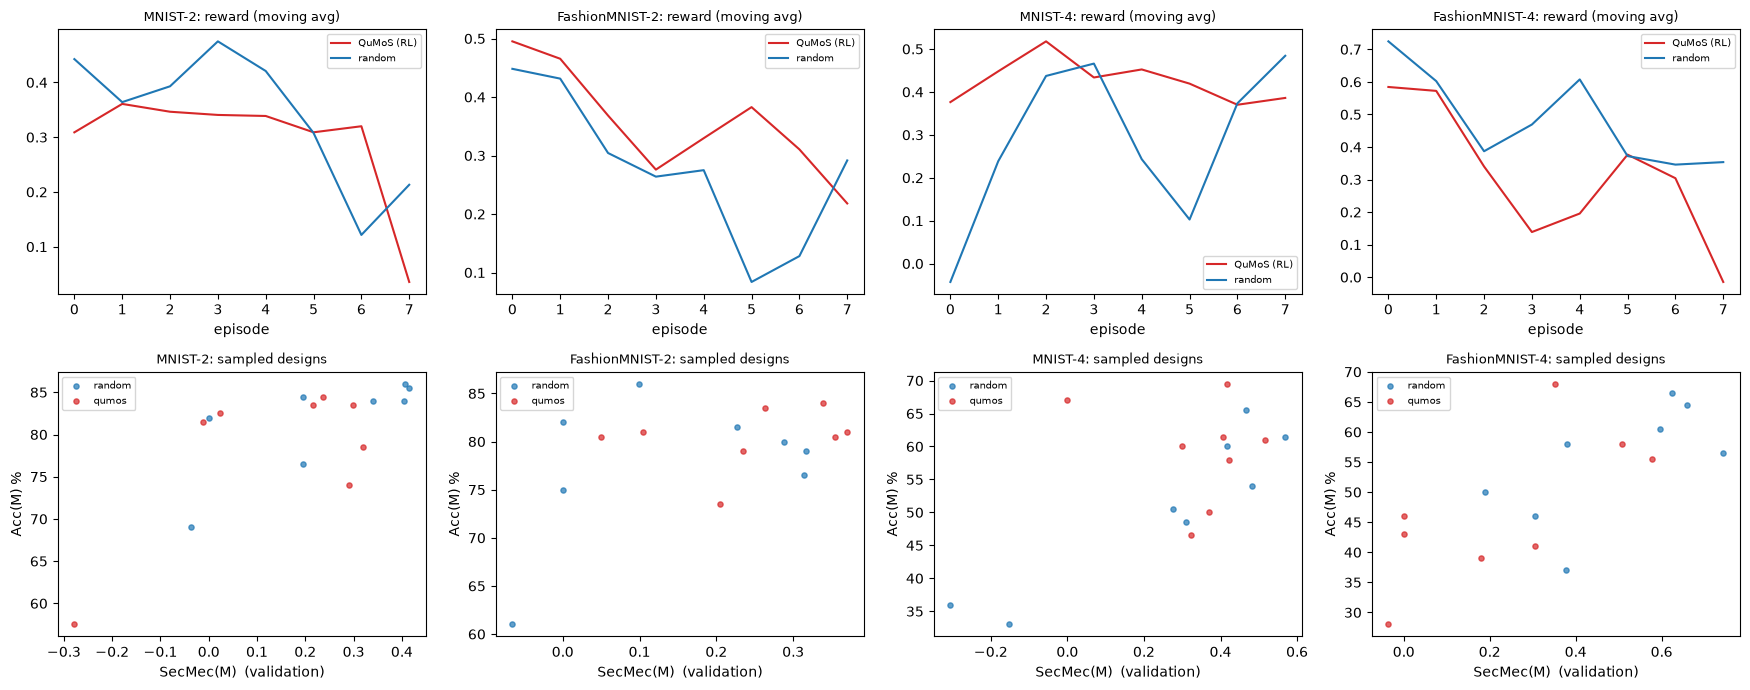

In [20]:
def moving(x, w): x = np.asarray(x, float); return np.array([x[max(0, i - w + 1):i + 1].mean() for i in range(len(x))])
fig, axes = plt.subplots(2, len(TASKS), figsize=(4.4 * len(TASKS), 7))
for k, t in enumerate(TASKS):
    H = HIST[t]; w = max(2, EPISODES // 6)
    axes[0, k].plot(moving([h["reward"] for h in H["qumos"]], w), label="QuMoS (RL)", color="#d62728"); axes[0, k].plot(moving([h["reward"] for h in H["random"]], w), label="random", color="#1f77b4")
    axes[0, k].set_title(f"{t}: reward (moving avg)", fontsize=9); axes[0, k].set_xlabel("episode"); axes[0, k].legend(fontsize=7)
    for name, col in (("random", "#1f77b4"), ("qumos", "#d62728")):
        axes[1, k].scatter([h["val_sec"] for h in H[name]], [100 * h["val_acc"] for h in H[name]], s=14, alpha=0.7, color=col, label=name)
    axes[1, k].set_xlabel("SecMec(M)  (validation)"); axes[1, k].set_ylabel("Acc(M) %"); axes[1, k].set_title(f"{t}: sampled designs", fontsize=9); axes[1, k].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Pareto frontier on MNIST-4 (Fig. 6) and the naive design (Fig. 7)

A design is on the Pareto frontier if no other design of the same search is better in both accuracy and security. The paper claims that every random design lies below the QuMoS frontier.
Fig. 7 compares the hand-made naive design with the most accurate QuMoS design: blue = `Acc(M)`, yellow = `SecAcc(M)`; when the bars are close, a single provider holds a model that is almost as good as the whole (low security).

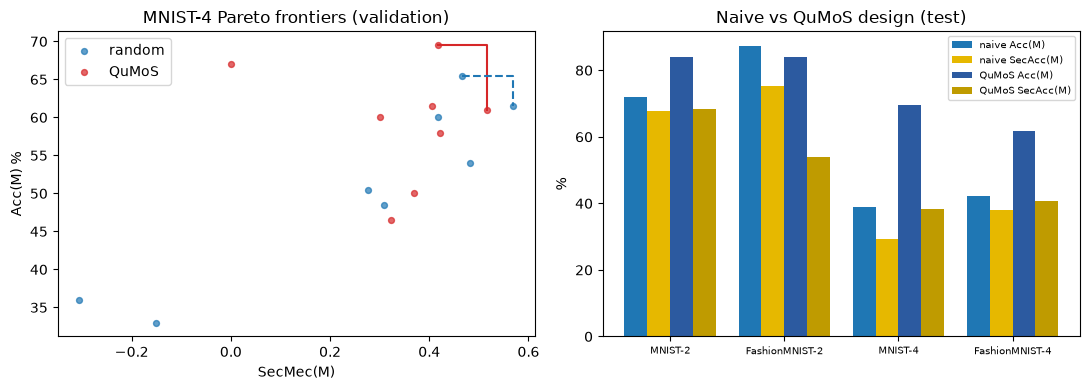

MNIST-4: fraction of random designs weakly dominated by the QuMoS frontier = 0.75; fraction of QuMoS designs dominated by the random frontier = 0.75


In [21]:
def pareto(points):
    pts = sorted(set(points), key=lambda p: (-p[0], -p[1])); front, best = [], -1
    for s, a in pts:
        if a > best: front.append((s, a)); best = a
    return sorted(front)
def dominated_fraction(front, pts):
    return np.mean([any(fs >= s and fa >= a for fs, fa in front) for s, a in pts])

H = HIST["MNIST-4"]
pq = [(h["val_sec"], 100 * h["val_acc"]) for h in H["qumos"]]; pr = [(h["val_sec"], 100 * h["val_acc"]) for h in H["random"]]
fq, fr = pareto(pq), pareto(pr)
dom_rand = dominated_fraction(fq, pr); dom_q = dominated_fraction(fr, pq)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(*zip(*pr), color="#1f77b4", s=18, alpha=0.7, label="random"); axes[0].scatter(*zip(*pq), color="#d62728", s=18, alpha=0.7, label="QuMoS")
axes[0].step(*zip(*fq), where="post", color="#d62728"); axes[0].step(*zip(*fr), where="post", color="#1f77b4", ls="--")
axes[0].set_xlabel("SecMec(M)"); axes[0].set_ylabel("Acc(M) %"); axes[0].set_title("MNIST-4 Pareto frontiers (validation)"); axes[0].legend()
xs = np.arange(len(TASKS)); w = 0.2
naive_acc = [RES[t]["naive"]["acc"] for t in TASKS]; naive_sec = [RES[t]["naive"]["sec_acc"] for t in TASKS]
q_acc = [RES[t]["qumos_acc"]["acc"] for t in TASKS]; q_sec = [RES[t]["qumos_acc"]["sec_acc"] for t in TASKS]
axes[1].bar(xs - 1.5 * w, naive_acc, w, color="#1f77b4", label="naive Acc(M)"); axes[1].bar(xs - 0.5 * w, naive_sec, w, color="#e6b800", label="naive SecAcc(M)")
axes[1].bar(xs + 0.5 * w, q_acc, w, color="#2c5aa0", label="QuMoS Acc(M)"); axes[1].bar(xs + 1.5 * w, q_sec, w, color="#bf9b00", label="QuMoS SecAcc(M)")
axes[1].set_xticks(xs); axes[1].set_xticklabels(list(TASKS), fontsize=7); axes[1].set_ylabel("%"); axes[1].set_title("Naive vs QuMoS design (test)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"MNIST-4: fraction of random designs weakly dominated by the QuMoS frontier = {dom_rand:.2f}; fraction of QuMoS designs dominated by the random frontier = {dom_q:.2f}")

### Robustness to the number of providers (Fig. 8)

On MNIST-4 the paper repeats the search with 2 providers (without `ibmq_belem`) and 4 providers (adding `ibmq_lima`) and reports the most accurate and the most secure design of each.

  QuMoS with 2 providers             8 episodes in   123s | best val acc 0.625 | max val SecMec 0.473 | mean reward last third 0.194


  QuMoS with 4 providers             8 episodes in    47s | best val acc 0.670 | max val SecMec 0.600 | mean reward last third 0.267


,providers,design,Acc(M) %,SecMec,SecAcc %,#QCP,#Node
0,2,acc,62.6667,0.0000,62.6667,1,7
1,2,sec,62.6667,0.0000,62.6667,1,7
2,3,acc,69.6667,0.4498,38.3333,2,7
3,3,sec,62.3333,0.5080,30.6667,2,6
4,4,acc,52.6667,0.0000,52.6667,1,1
5,4,sec,60.6667,0.4780,31.6667,2,5


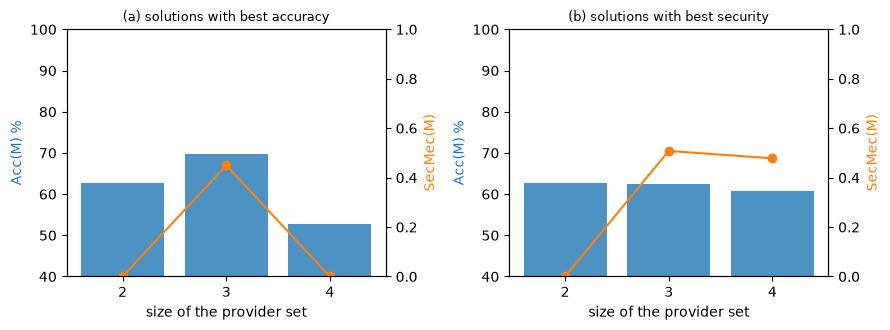

In [22]:
ROB = {}
for n_p, ids in ((2, (0, 2)), (3, (0, 1, 2)), (4, (0, 1, 2, 3))):
    if n_p == 3: hist = HIST["MNIST-4"]["qumos"]
    else: hist = run_search("MNIST-4", "rl", ROBUST_EPISODES, LAMBDA, SEED + 5000 + n_p, prov_ids=ids, label=f"QuMoS with {n_p} providers")
    floor = HIST["MNIST-4"]["floor"]
    ROB[n_p] = {"acc": test_scores("MNIST-4", select_design(hist, "acc", floor)), "sec": test_scores("MNIST-4", select_design(hist, "sec", floor))}
rob_df = pd.DataFrame([{"providers": n_p, "design": kind, "Acc(M) %": v["acc"], "SecMec": v["sec"], "SecAcc %": v["sec_acc"], "#QCP": v["n_qcp"], "#Node": v["n_nodes"]} for n_p, d in ROB.items() for kind, v in d.items()]).round(4)
display(rob_df)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, kind, ttl in zip(axes, ("acc", "sec"), ("(a) solutions with best accuracy", "(b) solutions with best security")):
    ps = sorted(ROB); ax.bar([str(p) for p in ps], [ROB[p][kind]["acc"] for p in ps], color="#1f77b4", alpha=0.8); ax.set_ylabel("Acc(M) %", color="#1f77b4"); ax.set_ylim(40, 100)
    ax2 = ax.twinx(); ax2.plot([str(p) for p in ps], [ROB[p][kind]["sec"] for p in ps], "o-", color="#ff7f0e"); ax2.set_ylabel("SecMec(M)", color="#ff7f0e"); ax2.set_ylim(0, 1); ax.set_xlabel("size of the provider set"); ax.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Everything the notebook trains or evaluates is a 4-qubit node circuit, so this section draws the circuits that are **actually executed**. Each drawing is a Qiskit circuit generated from the same gate list that the fast simulator and the noisy density-matrix simulator use; Section 3 asserted that they agree with Qiskit numerically, and the last cell of this section repeats the assertion for the *trained* complete QuMoS model that is drawn.

1. the five candidate trainable architectures `A1`-`A5`, each preceded by the image encoder (head node), with qubit count, depth and trainable-parameter count;
2. a node fed by two other nodes (stacked `ry` / `rx` encoders of the two children's outputs);
3. the partition found by QuMoS on MNIST-4 (most accurate design of the search): the tree with provider colours and security submodels, and the circuit of every distinct node that is shipped to a provider.

Assumptions where the paper is silent: exact wiring of the five Sim et al. circuits (re-drawn from the original figure, two repetitions), the form of the input encoder of nodes fed by other nodes, and the readout (Z on every qubit; the root uses the first `n_classes` qubits as class scores).

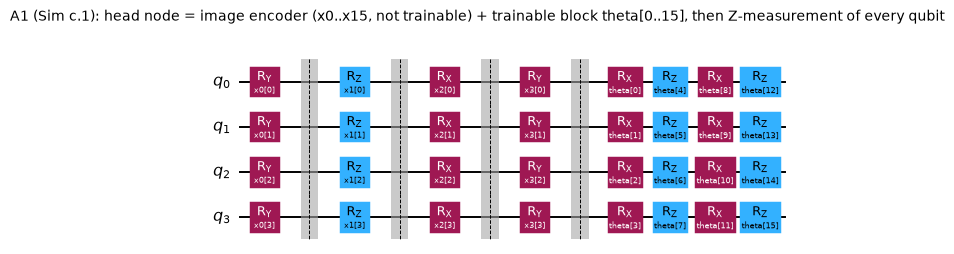

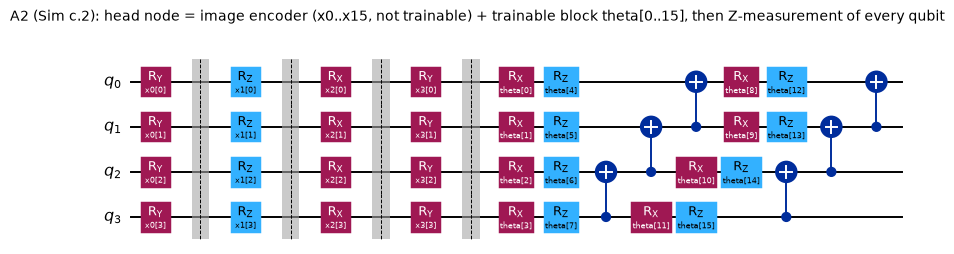

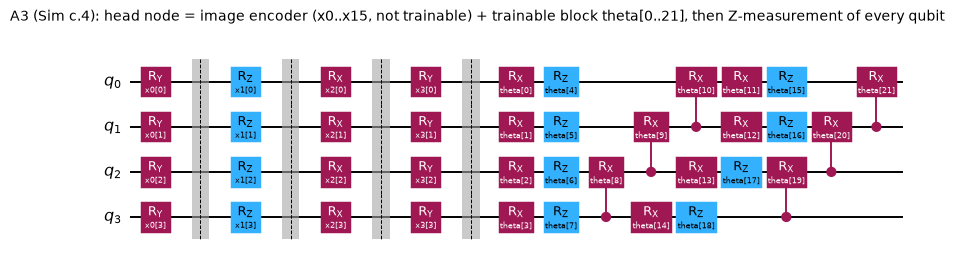

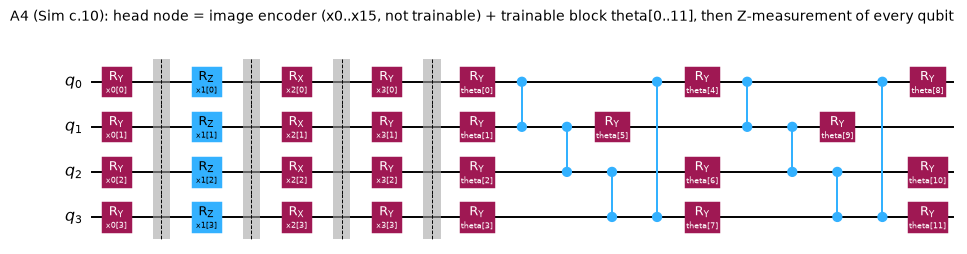

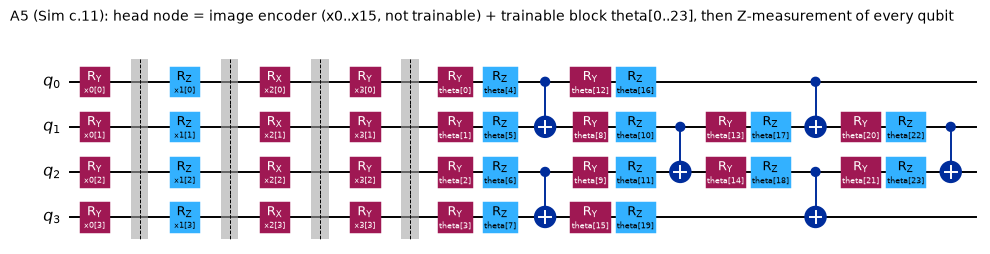

,architecture,qubits,depth,trainable parameters,two-qubit gates,gates
0,A1 (Sim c.1),4,8,16,0,32
1,A2 (Sim c.2),4,13,16,6,38
2,A3 (Sim c.4),4,13,22,6,38
3,A4 (Sim c.10),4,15,12,8,36
4,A5 (Sim c.11),4,16,24,6,46


In [23]:
def circuit_stats(qc):
    ops = qc.count_ops(); two_q = sum(v for k, v in ops.items() if k in ("cx", "cz", "crx"))
    return {"qubits": qc.num_qubits, "depth": qc.depth(filter_function=lambda i: i.operation.name != "barrier"), "trainable parameters": len([p for p in qc.parameters if p.name.startswith("theta")]), "two-qubit gates": two_q, "gates": sum(v for k, v in ops.items() if k != "barrier")}
def show_circuit(qc, title):
    fig = qc.draw("mpl", fold=40, scale=0.7); fig.suptitle(title, fontsize=10, y=1.02); display(fig); plt.close(fig)

STATS = []
for a in LAYERS:
    qc = qiskit_node(a, slots=[(ax, None) for ax in IMG_AXES], name=ARCH_NAMES[a], symbolic=True)
    show_circuit(qc, f"{ARCH_NAMES[a]}: head node = image encoder (x0..x15, not trainable) + trainable block theta[0..{NP[a] - 1}], then Z-measurement of every qubit")
    STATS.append({"architecture": ARCH_NAMES[a], **circuit_stats(qc)})
display(pd.DataFrame(STATS))

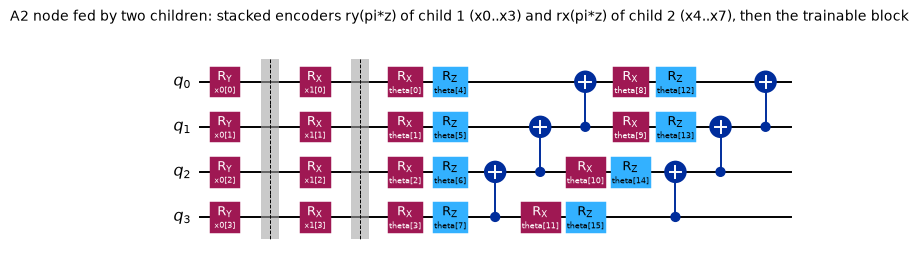

node with two children: {'qubits': 4, 'depth': 11, 'trainable parameters': 16, 'two-qubit gates': 6, 'gates': 30}


In [24]:
qc2 = qiskit_node(2, slots=[("ry", None), ("rx", None)], name="A2 with two children", symbolic=True)
show_circuit(qc2, "A2 node fed by two children: stacked encoders ry(pi*z) of child 1 (x0..x3) and rx(pi*z) of child 2 (x4..x7), then the trainable block")
print("node with two children:", circuit_stats(qc2))

### The partition found by QuMoS on MNIST-4

Most accurate QuMoS design on MNIST-4: architectures ['A3 (Sim c.4)', 'A3 (Sim c.4)', 'A3 (Sim c.4)', 'A3 (Sim c.4)', 'A3 (Sim c.4)', 'A3 (Sim c.4)', 'A3 (Sim c.4)'] | providers ['QCP 3', 'QCP 3', 'QCP 2', 'QCP 3', 'QCP 3', 'QCP 3', 'QCP 2']
test Acc(M) = 69.67 %, SecAcc = 38.33 %, SecMec = 0.450, 3 security submodels: [([1, 2, 4, 5], 'tail [1]'), ([6], 'tail [6]'), ([3, 7], 'tail [3]')]


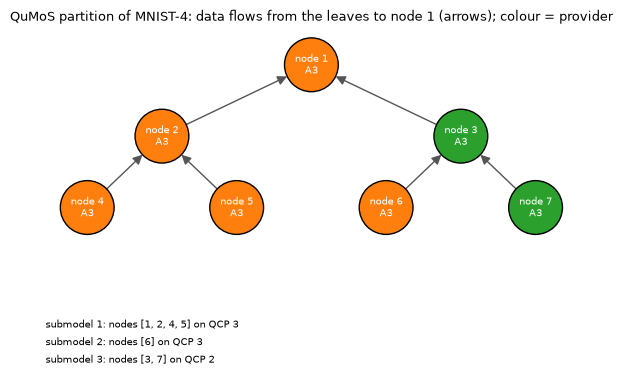

In [25]:
import networkx as nx
best_q = RES["MNIST-4"]["qumos_acc"]; arch_b, prov_b = best_q["arch"], best_q["prov"]; act_b = active_nodes(arch_b)
subs = security_submodels(arch_b, prov_b)
print("Most accurate QuMoS design on MNIST-4: architectures", [ARCH_NAMES[arch_b[n - 1]] for n in act_b], "| providers", [PROVIDERS[prov_b[n - 1]][:5] for n in act_b])
print(f"test Acc(M) = {best_q['acc']:.2f} %, SecAcc = {best_q['sec_acc']:.2f} %, SecMec = {best_q['sec']:.3f}, {len(subs)} security submodels:", [(c['nodes'], f"tail {c['tails']}") for c in subs])
G = nx.DiGraph(); G.add_nodes_from(act_b); G.add_edges_from(edges_of(act_b))
pos = {}
for n in act_b:
    depth = int(math.log2(n)); idx = n - 2 ** depth; pos[n] = ((idx + 0.5) / 2 ** depth, -depth)
PROV_COL = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]
fig, ax = plt.subplots(figsize=(7, 3.8))
nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowstyle="-|>", arrowsize=14, node_size=1500, edge_color="#555555")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=1500, node_color=[PROV_COL[prov_b[n - 1]] for n in act_b], edgecolors="black")
nx.draw_networkx_labels(G, pos, ax=ax, labels={n: f"node {n}\n{ARCH_NAMES[arch_b[n - 1]].split()[0]}" for n in act_b}, font_size=7, font_color="white")
for i, c in enumerate(subs):
    xs = [pos[n][0] for n in c["nodes"]]; ys = [pos[n][1] for n in c["nodes"]]
    ax.annotate(f"submodel {i + 1}: nodes {c['nodes']} on {PROVIDERS[prov_b[c['nodes'][0] - 1]][:5]}", xy=(0.01, -0.02 - 0.06 * i), xycoords="axes fraction", fontsize=7)
ax.set_title("QuMoS partition of MNIST-4: data flows from the leaves to node 1 (arrows); colour = provider", fontsize=9); ax.axis("off"); ax.set_ylim(-3.6, 0.5)
plt.show()

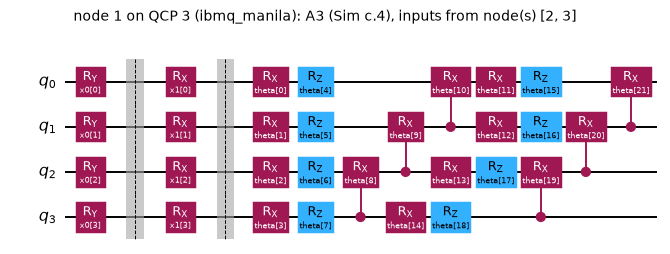

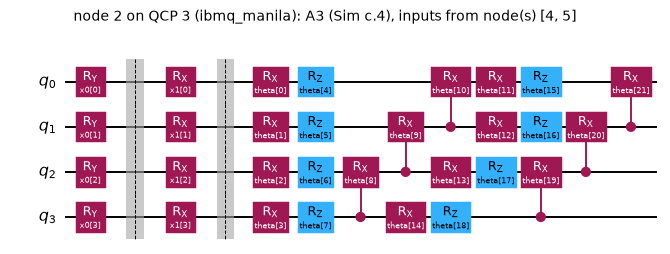

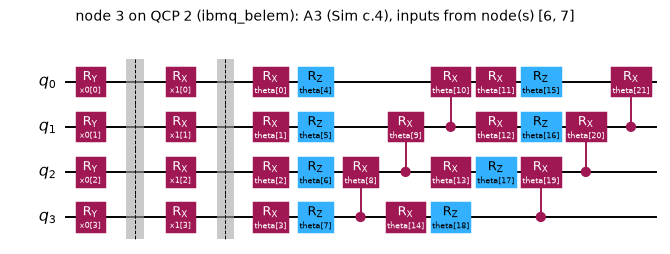

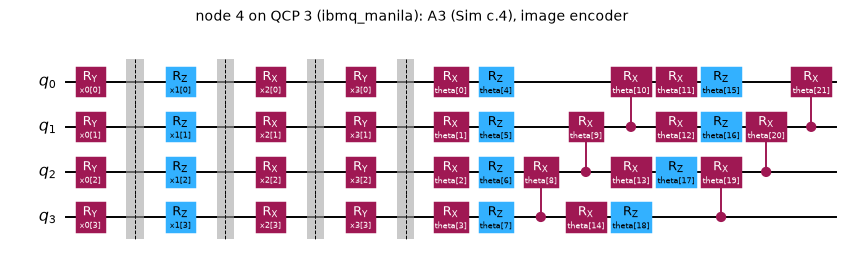

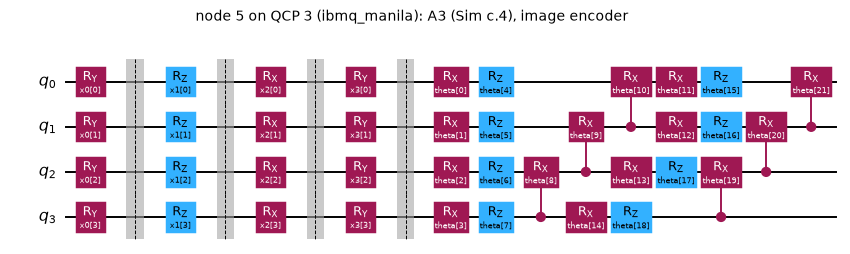

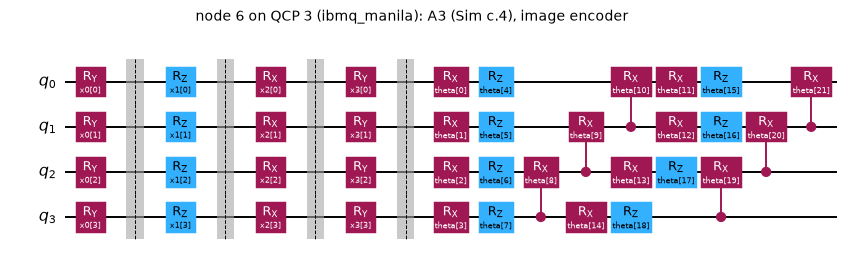

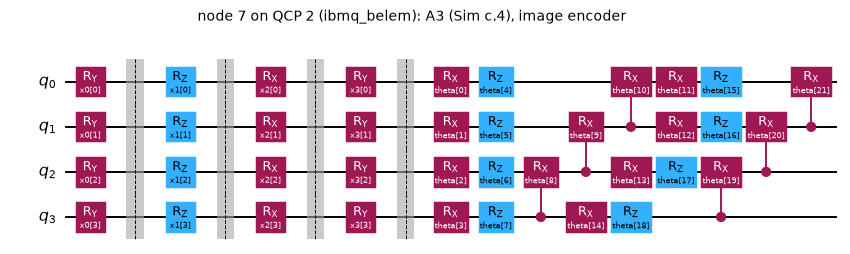

,node,provider,architecture,inputs,qubits,depth,trainable parameters,two-qubit gates,gates
0,1,QCP 3 (ibmq_manila),A3 (Sim c.4),"nodes [2, 3]",4,11,22,6,30
1,2,QCP 3 (ibmq_manila),A3 (Sim c.4),"nodes [4, 5]",4,11,22,6,30
2,3,QCP 2 (ibmq_belem),A3 (Sim c.4),"nodes [6, 7]",4,11,22,6,30
3,4,QCP 3 (ibmq_manila),A3 (Sim c.4),image,4,13,22,6,38
4,5,QCP 3 (ibmq_manila),A3 (Sim c.4),image,4,13,22,6,38
5,6,QCP 3 (ibmq_manila),A3 (Sim c.4),image,4,13,22,6,38
6,7,QCP 2 (ibmq_belem),A3 (Sim c.4),image,4,13,22,6,38


trained QuMoS model: max |fast simulator - Qiskit Statevector circuits| on 5 test images = 1.11e-15


In [26]:
rows = []
for n in act_b:
    a = arch_b[n - 1]; kids = [c for c in children(n) if c in act_b]
    slots_sym = [(ax_, None) for ax_ in IMG_AXES] if not kids else [(ax_, None) for ax_ in ("ry", "rx")[:len(kids)]]
    qc = qiskit_node(a, slots=slots_sym, name=f"node {n}", symbolic=True)
    show_circuit(qc, f"node {n} on {PROVIDERS[prov_b[n - 1]]}: {ARCH_NAMES[a]}, " + ("image encoder" if not kids else f"inputs from node(s) {kids}"))
    rows.append({"node": n, "provider": PROVIDERS[prov_b[n - 1]], "architecture": ARCH_NAMES[a], "inputs": "image" if not kids else f"nodes {kids}", **circuit_stats(qc)})
display(pd.DataFrame(rows))

# executed == drawn: run the trained complete model with Qiskit Statevector circuits node by node and compare with the fast simulator
model_b = train_model("MNIST-4", arch_b); ang_t = DATA["MNIST-4"]["test"]["ang"][:5]
z_fast = run_nodes(model_b, act_b, ang_t, "free", U=build_unitaries([arch_b[n - 1] for n in act_b], model_b["theta"]))[1].numpy(); z_q = np.zeros_like(z_fast)
for b in range(5):
    outs = {}
    for n in sorted(act_b, reverse=True):
        kids = [c for c in children(n) if c in act_b]
        sl = [(ax_, ang_t[b, 4 * j:4 * j + 4].numpy()) for j, ax_ in enumerate(IMG_AXES)] if not kids else [(ax_, math.pi * outs[c]) for ax_, c in zip(("ry", "rx"), kids)]
        outs[n] = qiskit_z(qiskit_node(arch_b[n - 1], model_b["theta"][model_b["row"][n], :NP[arch_b[n - 1]]].numpy(), sl))
    z_q[b] = outs[1]
print("trained QuMoS model: max |fast simulator - Qiskit Statevector circuits| on 5 test images =", f"{np.abs(z_fast - z_q).max():.2e}")
assert np.abs(z_fast - z_q).max() < 1e-9

## 8. Side by side with the paper

The paper's Table I (best entry per dataset) and the other checkable statements are compared with this notebook's numbers. A numeric claim is *reproduced* if our value is within the tolerance (2 accuracy points; 0.05 for `SecMec`), otherwise *not reached* (we are worse) or *exceeded* (we are better); ordering claims are checked as inequalities. Our budgets are far below the paper's (a few hundred training images, a few epochs, tens instead of 200 episodes, one seed), so absolute numbers are expected to differ; the table says exactly where.

In [27]:
PAPER = {   # Table I of the paper: (Acc %, SecMec, SecAcc %)
    "MNIST-2":        {"nas": [94.67, 95.33, 95.33], "random_acc": (94.67, 0.0246, 92.33), "random_sec": (90.67, 0.4926, 46.00), "qumos_acc": (94.67, 0.4401, 53.00), "qumos_sec": (91.33, 0.5547, 40.67)},
    "FashionMNIST-2": {"nas": [95.67, 95.33, 94.67], "random_acc": (92.67, 0.0971, 83.67), "random_sec": (90.67, 0.4596, 49.00), "qumos_acc": (94.00, 0.3298, 63.00), "qumos_sec": (91.33, 0.4745, 48.00)},
    "MNIST-4":        {"nas": [74.67, 75.67, 75.67], "random_acc": (72.67, 0.5046, 36.00), "random_sec": (68.67, 0.6505, 24.00), "qumos_acc": (76.33, 0.6245, 28.67), "qumos_sec": (72.00, 0.7917, 15.00)},
    "FashionMNIST-4": {"nas": [79.00, 80.33, 81.67], "random_acc": (78.67, 0.4025, 47.00), "random_sec": (72.67, 0.7110, 21.00), "qumos_acc": (80.67, 0.5620, 35.33), "qumos_sec": (73.33, 0.9409, 4.33)},
}
VR = []
def add(claim, task, paper, ours, verdict): VR.append({"claim": claim, "task": task, "paper": paper, "this notebook": ours, "verdict": verdict})
def num_verdict(ours, paper, tol):
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")
def order_verdict(cond): return "reproduced" if cond else "not reached"

for t in TASKS:
    P, R = PAPER[t], RES[t]; base_p = max(P["nas"]); base_n = max(v["acc"] for v in R["nas"].values())
    add("C1 best NAS-single accuracy (baseline)", t, f"{base_p:.2f} %", f"{base_n:.2f} %", num_verdict(base_n, base_p, 2.0))
    gap = R["qumos_acc"]["acc"] - base_n
    add("C2 QuMoS most-accurate design loses <= 2 points vs baseline", t, f"{P['qumos_acc'][0] - base_p:+.2f} pts", f"{gap:+.2f} pts", order_verdict(gap >= -2.0))
    add("C3 QuMoS most-accurate design: Acc(M)", t, f"{P['qumos_acc'][0]:.2f} %", f"{R['qumos_acc']['acc']:.2f} %", num_verdict(R["qumos_acc"]["acc"], P["qumos_acc"][0], 2.0))
    add("C4 QuMoS acc-best has higher SecMec than random acc-best", t, f"{P['qumos_acc'][1]:.3f} > {P['random_acc'][1]:.3f}", f"{R['qumos_acc']['sec']:.3f} vs {R['random_acc']['sec']:.3f}", order_verdict(R["qumos_acc"]["sec"] > R["random_acc"]["sec"]))
    add("C5 QuMoS acc-best Acc(M) >= random acc-best", t, f"{P['qumos_acc'][0]:.2f} >= {P['random_acc'][0]:.2f}", f"{R['qumos_acc']['acc']:.2f} vs {R['random_acc']['acc']:.2f}", order_verdict(R["qumos_acc"]["acc"] >= R["random_acc"]["acc"]))
    add("C6 QuMoS security-best has higher SecMec than random security-best", t, f"{P['qumos_sec'][1]:.3f} > {P['random_sec'][1]:.3f}", f"{R['qumos_sec']['sec']:.3f} vs {R['random_sec']['sec']:.3f}", order_verdict(R["qumos_sec"]["sec"] > R["random_sec"]["sec"]))
    add("C7 QuMoS security-best: SecMec value", t, f"{P['qumos_sec'][1]:.3f}", f"{R['qumos_sec']['sec']:.3f}", num_verdict(R["qumos_sec"]["sec"], P["qumos_sec"][1], 0.05))
    add("C8 QuMoS acc-best: SecMec value", t, f"{P['qumos_acc'][1]:.3f}", f"{R['qumos_acc']['sec']:.3f}", num_verdict(R["qumos_acc"]["sec"], P["qumos_acc"][1], 0.05))
    add("C9 naive design is less secure than QuMoS acc-best (Fig. 7)", t, "naive SecAcc close to Acc", f"naive SecMec {R['naive']['sec']:.3f} vs QuMoS {R['qumos_acc']['sec']:.3f}", order_verdict(R["naive"]["sec"] < R["qumos_acc"]["sec"]))
add("C10 every random design lies under the QuMoS Pareto frontier (Fig. 6)", "MNIST-4", "100 % dominated", f"{100 * dom_rand:.0f} % dominated", order_verdict(dom_rand >= 0.999))
add("C11 QuMoS frontier dominates at least as many random designs as vice versa (Fig. 6)", "MNIST-4", "yes", f"{100 * dom_rand:.0f} % vs {100 * dom_q:.0f} %", order_verdict(dom_rand >= dom_q))
add("C12 2 providers: security-best accuracy within 2 points of the 3-provider design (Fig. 8)", "MNIST-4", "+1.33 pts", f"{ROB[2]['sec']['acc'] - ROB[3]['sec']['acc']:+.2f} pts", order_verdict(abs(ROB[2]['sec']['acc'] - ROB[3]['sec']['acc']) <= 2.0))
add("C13 2 providers: security-best SecMec within 0.1 of the 3-provider design (Fig. 8)", "MNIST-4", "-0.064", f"{ROB[2]['sec']['sec'] - ROB[3]['sec']['sec']:+.3f}", order_verdict(abs(ROB[2]['sec']['sec'] - ROB[3]['sec']['sec']) <= 0.1))
add("C14 4 providers: security degrades slightly vs 3 providers (Fig. 8b)", "MNIST-4", "SecMec(4) < SecMec(3)", f"{ROB[4]['sec']['sec']:.3f} vs {ROB[3]['sec']['sec']:.3f}", order_verdict(ROB[4]['sec']['sec'] < ROB[3]['sec']['sec']))
add("C15 200-episode search, full data, 20 epochs, noisy-aware training", "all", "paper budget", f"{EPISODES} episodes, {TRAIN_N} images, {EPOCHS} epochs", "cannot be checked")
VERDICTS = pd.DataFrame(VR)
display(VERDICTS)
print("\nVerdict counts:"); print(VERDICTS["verdict"].value_counts().to_string())

,claim,task,paper,this notebook,verdict
0,C1 best NAS-single accuracy (baseline),MNIST-2,95.33 %,87.00 %,not reached
1,C2 QuMoS most-accurate design loses <= 2 points vs baseline,MNIST-2,-0.66 pts,-3.00 pts,not reached
2,C3 QuMoS most-accurate design: Acc(M),MNIST-2,94.67 %,84.00 %,not reached
3,C4 QuMoS acc-best has higher SecMec than random acc-best,MNIST-2,0.440 > 0.025,0.187 vs 0.358,not reached
4,C5 QuMoS acc-best Acc(M) >= random acc-best,MNIST-2,94.67 >= 94.67,84.00 vs 84.67,not reached
5,C6 QuMoS security-best has higher SecMec than random security-best,MNIST-2,0.555 > 0.493,0.216 vs 0.319,not reached
6,C7 QuMoS security-best: SecMec value,MNIST-2,0.555,0.216,not reached
7,C8 QuMoS acc-best: SecMec value,MNIST-2,0.440,0.187,not reached
8,C9 naive design is less secure than QuMoS acc-best (Fig. 7),MNIST-2,naive SecAcc close to Acc,naive SecMec 0.060 vs QuMoS 0.187,reproduced
9,C1 best NAS-single accuracy (baseline),FashionMNIST-2,95.67 %,86.00 %,not reached



Verdict counts:
verdict
not reached          27
reproduced           14
cannot be checked     1


In [28]:
summary = []
for t in TASKS:
    R = RES[t]; P = PAPER[t]
    summary.append({"task": t, "paper NAS-single best %": max(P["nas"]), "ours NAS-single best %": round(max(v["acc"] for v in R["nas"].values()), 2),
                    "paper QuMoS acc-best (Acc %, SecMec)": f"{P['qumos_acc'][0]:.2f}, {P['qumos_acc'][1]:.3f}", "ours": f"{R['qumos_acc']['acc']:.2f}, {R['qumos_acc']['sec']:.3f}",
                    "paper QuMoS sec-best": f"{P['qumos_sec'][0]:.2f}, {P['qumos_sec'][1]:.3f}", "ours ": f"{R['qumos_sec']['acc']:.2f}, {R['qumos_sec']['sec']:.3f}",
                    "paper random acc/sec-best SecMec": f"{P['random_acc'][1]:.3f} / {P['random_sec'][1]:.3f}", "ours  ": f"{R['random_acc']['sec']:.3f} / {R['random_sec']['sec']:.3f}"})
display(pd.DataFrame(summary).set_index("task").T)
print("Classical models on the same 4x4 inputs (test accuracy %):"); display(CLASSICAL_TABLE)
print(f"Total wall-clock of the notebook run: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min")

task,MNIST-2,FashionMNIST-2,MNIST-4,FashionMNIST-4
paper NAS-single best %,95.33,95.67,75.67,81.67
ours NAS-single best %,87.0,86.0,68.33,73.67
"paper QuMoS acc-best (Acc %, SecMec)","94.67, 0.440","94.00, 0.330","76.33, 0.625","80.67, 0.562"
ours,"84.00, 0.187","84.00, 0.357","69.67, 0.450","61.67, 0.341"
paper QuMoS sec-best,"91.33, 0.555","91.33, 0.474","72.00, 0.792","73.33, 0.941"
ours,"81.67, 0.216","86.67, 0.388","62.33, 0.508","61.67, 0.341"
paper random acc/sec-best SecMec,0.025 / 0.493,0.097 / 0.460,0.505 / 0.650,0.403 / 0.711
ours,0.358 / 0.319,0.053 / 0.335,0.440 / 0.653,0.658 / 0.653


Classical models on the same 4x4 inputs (test accuracy %):


,"SVC (rbf, C=1)",RandomForest (200),"MLP (32,16)",Logistic regression
MNIST-2,97.33,95.33,97.67,97.00
FashionMNIST-2,91.00,92.67,92.33,90.00
MNIST-4,91.00,89.33,91.67,87.67
FashionMNIST-4,83.67,83.67,83.67,82.67


Total wall-clock of the notebook run: 32.8 min


## 9. Reading the paper critically

* **The security measure rewards a weak attacker.** `SecAcc` is the accuracy of a submodel that is *run as is*. A submodel whose end node is not the root was never trained to output class scores, so its argmax is close to chance (or even below it), whatever information its circuit holds. A real adversary would train a new read-out on the stolen sub-circuit, query the service for labels (model extraction) and fine-tune; `SecMec` says nothing about those stronger attacks. The "less than chance" `SecAcc` entries of Table I (for example 4.33 %) show the metric measures *mismatch*, not information content.
* **The threat model is narrow.** QuMoS assumes that the providers do not collude and that every node is sent to a different provider, and it protects only the circuit `C(theta)`, not the user's data or the intermediate outputs, which are classical numbers visible to the QML service and in every provider's log.
* **Accuracy is measured on 300 test images that also drive the search** in the paper (reward and final numbers use the same images), which biases the reported accuracies upward. Here the search uses a separate validation split.
* **Small effects, one seed.** The differences between NAS-single providers (a fraction of a point) are within the sampling error of 300 test images (about 2-3 points of standard error); a single search run per setting cannot separate them. Differences between random search and the RL controller after tens of episodes are dominated by luck; the paper itself runs a single 200-episode search.
* **Noise is modelled coarsely.** Depolarizing channels with average gate errors and no routing underestimate the error of a real device, and the three simulated devices differ mostly in their CNOT error, so "different providers" differ in noise level rather than in a hard-to-replicate hardware signature.
* **Cost of the defence.** Several providers mean several queue times and several calls per inference, and the tree needs 7 circuit executions instead of 1.

* **What this small-budget run shows.** With 8 episodes per search, 320 training images and 6 epochs, our best complete models reach 82-88 % (2 classes) and 62-74 % (4 classes) on the 300 test images, well below the paper's 95 % and 76-82 %; a classical SVC/MLP on the same 4x4 inputs reaches 90-98 % (2 classes) and 83-92 % (4 classes), so the quantum nodes are under-trained rather than limited by the input. The ordering claims of the paper (QuMoS beats random search in `SecMec` at similar accuracy, its Pareto frontier dominates random designs) hold on some tasks (Fashion-MNIST-2, MNIST-4 for the most accurate design) and fail on others; with 8 samples per search and a single seed this is within what luck can produce, and it neither confirms nor refutes the paper's 200-episode result. What does hold everywhere is the qualitative point of Fig. 7: the hand-made naive split has a clearly lower `SecMec` than the design found by the search.
* **Negative or tiny `SecMec`.** `SecMec` can be negative (a submodel that happens to beat the complete model on these few images) and, when the search puts everything on one provider (the 2- and 4-provider runs on MNIST-4 each ended with an all-on-one-provider "best accuracy" design), it is exactly 0; the metric is as noisy as the 300-image accuracy it divides.


## 10. Exercises

1. **Stronger attacker.** For the most secure QuMoS design, let the attacker train a linear read-out on the `4` Z-expectations of the stolen sub-circuit with 100 labelled images (obtained by querying the service). How much accuracy does it recover? What does that do to `SecMec`?
2. **Colluding providers.** Allow two providers to pool their submodels (merge the components of two providers). How does the best-security design change, and how many providers must collude to rebuild the full model?
3. **Lambda sweep.** Repeat the MNIST-4 search with `LAMBDA` in {0.1, 0.5, 1.0} and plot the three Pareto frontiers. Which value gives the best accuracy at `SecMec > 0.5`?
4. **Better filler.** The attacker feeds the 2x2 average-pooled image to missing inputs. Replace it by zeros, by random angles, or by a learned constant and measure how `SecAcc` changes.
5. **Noise-aware training.** Train each node with the provider noise of its provider (use `node_density` in the training loop for a few epochs) and compare `Acc(M)` with the noise-free training used here.